In [1]:
# ============================================================
#  02_weather_cities_models — Setup
# ============================================================
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    HAS_SARIMAX = True
except ImportError:
    HAS_SARIMAX = False

try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110


def find_project_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for parent in [p, *p.parents]:
        if (parent / "requirements.txt").exists() and (parent / "notebooks").exists():
            return parent
    raise RuntimeError("Корень проекта не найден")


PROJECT = find_project_root()
DATA_DIR = PROJECT / "data" / "weather" / "cities"
ARTIFACTS_DIR = PROJECT / "artifacts" / "weather" / "cities"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT      :", PROJECT)
print("DATA_DIR     :", DATA_DIR)
print("ARTIFACTS_DIR:", ARTIFACTS_DIR)
print(f"backend      : xgboost={HAS_XGB}, sarimax={HAS_SARIMAX}, torch={HAS_TORCH}")
if not HAS_SARIMAX:
    print("⚠  statsmodels не установлен → SARIMAX будет пропущен (метрики = 0). "
          "Установи: pip install statsmodels")
if not HAS_XGB:
    print("⚠  xgboost не установлен → фолбэк на HistGradientBoostingRegressor.")
if not HAS_TORCH:
    print("ℹ  torch не установлен → LSTM будет пропущен.")

PROJECT      : /app
DATA_DIR     : /app/data/weather/cities
ARTIFACTS_DIR: /app/artifacts/weather/cities
backend      : xgboost=True, sarimax=True, torch=True


In [2]:
# ============================================================
#  Конфиг задачи + загрузка cities_daily.csv
# ============================================================
TRAIN_END  = pd.Timestamp("2021-12-31")
TEST_START = pd.Timestamp("2022-01-01")
TEST_END   = pd.Timestamp("2023-12-31")

# Горизонты
STATION_HORIZONS = list(range(1, 15))       # 1..14
CITY_HORIZONS    = list(range(1, 8))        # 1..7

# Окно для city-dashboard (совпадает со структурой фронта)
CITY_N          = 66
CITY_PAST       = 59
CITY_BACK_START = 45
CITY_ORIGIN     = 44

# Переменные
VARS = ["temp", "humidity", "precipitation", "wind", "pressure"]
CITY_VAR_MAP = {
    "temp": "temp",
    "hum":  "humidity",
    "rain": "precipitation",
    "wind": "wind",
    "pres": "pressure",
}
CITY_VAR_UNITS = {
    "temp": "°C", "hum": "%", "rain": "мм",
    "wind": "м/с", "pres": "гПа",
}

# Модели
STATION_MODELS = ["Persistence", "Seasonal Naive", "Ridge",
                  "RandomForest", "GradientBoosting", "XGBoost"]

CITY_MODELS = ["Persistence"]
if HAS_SARIMAX:
    CITY_MODELS.append("SARIMAX")
if HAS_XGB:
    CITY_MODELS.append("XGBoost")
if HAS_TORCH:
    CITY_MODELS.append("LSTM")
if "XGBoost" not in CITY_MODELS:
    CITY_MODELS.append("XGBoost")   # останется на HistGradientBoosting-фолбэке

cities_daily = pd.read_csv(DATA_DIR / "cities_daily.csv", parse_dates=["date"])
cities_daily = cities_daily.sort_values(["city", "date"]).reset_index(drop=True)

meta = json.loads((DATA_DIR / "cities_daily_meta.json").read_text())

CITY_NAMES = sorted(cities_daily["city"].unique())
CITY_INFO  = {c["city"]: c for c in meta["cities"]}

print(f"Загружено: {cities_daily.shape}")
print(f"Города   : {CITY_NAMES}")
print(f"Период   : {cities_daily['date'].min().date()} → {cities_daily['date'].max().date()}")
print(f"Модели-станции : {STATION_MODELS}")
print(f"Модели-города  : {CITY_MODELS}")

Загружено: (64284, 11)
Города   : ['Almaty', 'Moscow', 'Sarajevo', 'Tbilisi']
Период   : 1980-01-01 → 2023-12-31
Модели-станции : ['Persistence', 'Seasonal Naive', 'Ridge', 'RandomForest', 'GradientBoosting', 'XGBoost']
Модели-города  : ['Persistence', 'SARIMAX', 'XGBoost', 'LSTM']


In [3]:
# ============================================================
#  Метрики (единый формат для обоих дашбордов)
# ============================================================

def safe_mape(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """MAPE, пропускающий |y_true| < 1e-6 (осадки, ветер)."""
    mask = np.abs(y_true) >= 1e-6
    if mask.sum() == 0:
        return 0.0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


def compute_metrics(y_true, y_pred, baseline_mae: float | None = None) -> dict:
    """Единый набор метрик, который ждёт фронт."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = min(len(y_true), len(y_pred))
    if n == 0:
        return dict(mae=0.0, rmse=0.0, r2=0.0, mape=0.0,
                    bias=0.0, maxError=0.0, medae=0.0, skill=0.0)

    yt, yp = y_true[:n], y_pred[:n]
    err  = yp - yt
    abse = np.abs(err)

    mae   = float(np.mean(abse))
    rmse  = float(np.sqrt(np.mean(err ** 2)))
    ssr   = float(np.sum(err ** 2))
    sst   = float(np.sum((yt - yt.mean()) ** 2))
    r2    = float(1 - ssr / sst) if sst > 0 else 0.0
    mape  = safe_mape(yt, yp)
    bias  = float(np.mean(err))
    mx    = float(np.max(abse)) if n else 0.0
    medae = float(np.median(abse))
    skill = float(1 - mae / baseline_mae) if baseline_mae and baseline_mae > 0 else 0.0

    return dict(mae=mae, rmse=rmse, r2=r2, mape=mape,
                bias=bias, maxError=mx, medae=medae, skill=skill)


def holidays_for(dates: pd.Series) -> list[dict]:
    """Мини-календарь праздников для reference-lines на графике станций."""
    out = []
    for d in dates:
        md = (d.month, d.day)
        if md == (1, 1):
            out.append({"date": d.strftime("%Y-%m-%d"), "icon": "🎄", "label": "Новый год"})
        elif md == (7, 1):
            out.append({"date": d.strftime("%Y-%m-%d"), "icon": "☀️", "label": "Середина года"})
    return out

In [4]:
# ============================================================
#  Признаки: лаги (включая lag_0 = текущее значение),
#            rolling, сезонные sin/cos, месяц.
# ============================================================
LAGS = [0, 1, 2, 3, 7, 14, 30]      # lag_0 — текущее значение y(t)
ROLL_WINDOWS = [7, 30]


def build_features(series: pd.Series, dates: pd.Series,
                   target_lag_max: int = 30) -> pd.DataFrame:
    """
    Строит признаковый фрейм для регрессионных моделей.
    lag_0 = текущее значение y(t)  → модель видит «сегодня»,
    lag_k = y(t - k)               → и всю недавнюю историю.
    """
    df = pd.DataFrame({"y": series.values, "date": dates.values})
    for lag in LAGS:
        df[f"lag_{lag}"] = df["y"].shift(lag)      # lag=0 → без сдвига
    for w in ROLL_WINDOWS:
        df[f"roll_mean_{w}"] = df["y"].shift(1).rolling(w).mean()
        df[f"roll_std_{w}"]  = df["y"].shift(1).rolling(w).std()
    doy = pd.to_datetime(df["date"]).dt.dayofyear
    df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    df["month"]   = pd.to_datetime(df["date"]).dt.month
    return df


FEATURE_COLS = (
    [f"lag_{l}" for l in LAGS]
    + [f"roll_mean_{w}" for w in ROLL_WINDOWS]
    + [f"roll_std_{w}"  for w in ROLL_WINDOWS]
    + ["doy_sin", "doy_cos", "month"]
)


def make_supervised(df_feat: pd.DataFrame, horizon: int):
    """X — признаки на день t, y — значение через h дней."""
    X = df_feat[FEATURE_COLS].copy()
    y = df_feat["y"].shift(-horizon).copy()
    dates = pd.to_datetime(df_feat["date"])
    mask = X.notna().all(axis=1) & y.notna()
    return X[mask], y[mask], dates[mask]


print(f"LAGS          : {LAGS}")
print(f"FEATURE_COLS  : {FEATURE_COLS}")

LAGS          : [0, 1, 2, 3, 7, 14, 30]
FEATURE_COLS  : ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_30', 'roll_mean_7', 'roll_mean_30', 'roll_std_7', 'roll_std_30', 'doy_sin', 'doy_cos', 'month']


In [5]:
# ============================================================
#  Обёртки моделей + multi-step backtest
# ============================================================

def _fit_regressor(model_name: str, X_tr: np.ndarray, y_tr: np.ndarray):
    if model_name == "Ridge":
        scaler = StandardScaler().fit(X_tr)
        m = Ridge(alpha=1.0).fit(scaler.transform(X_tr), y_tr)
        return lambda X: m.predict(scaler.transform(X)), m

    if model_name == "RandomForest":
        m = RandomForestRegressor(n_estimators=200, max_depth=15,
                                  n_jobs=-1, random_state=42).fit(X_tr, y_tr)
        return lambda X: m.predict(X), m

    if model_name == "GradientBoosting":
        m = GradientBoostingRegressor(n_estimators=150, learning_rate=0.05,
                                      max_depth=4, random_state=42).fit(X_tr, y_tr)
        return lambda X: m.predict(X), m

    if model_name == "XGBoost":
        if HAS_XGB:
            m = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                                 subsample=0.9, colsample_bytree=0.9,
                                 n_jobs=-1, random_state=42, verbosity=0).fit(X_tr, y_tr)
            return lambda X: m.predict(X), m
        from sklearn.ensemble import HistGradientBoostingRegressor
        print("    [XGBoost] пакет не найден — fallback на HistGradientBoostingRegressor")
        m = HistGradientBoostingRegressor(
            max_iter=300, learning_rate=0.05, max_depth=6,
            random_state=42).fit(X_tr, y_tr)
        return lambda X: m.predict(X), m

    raise ValueError(f"unknown regressor: {model_name}")


def _fit_sarimax(y_tr: np.ndarray, horizon: int, h_max: int):
    """SARIMAX(1,0,1)(1,0,1,365)."""
    if not HAS_SARIMAX:
        return None, None
    try:
        model = SARIMAX(y_tr, order=(1, 0, 1), seasonal_order=(1, 0, 1, 365),
                        enforce_stationarity=False, enforce_invertibility=False)
        res = model.fit(disp=False)
        fc = res.get_forecast(steps=horizon)
        mean = np.asarray(fc.predicted_mean)
        sd   = np.asarray(fc.se_mean)
        return mean, sd
    except Exception as e:
        print(f"    [SARIMAX] не сошёлся: {e}")
        return None, None


def rolling_backtest_station(series_df: pd.DataFrame,
                              model_name: str,
                              horizons: list[int],
                              train_end: pd.Timestamp,
                              test_start: pd.Timestamp,
                              test_end: pd.Timestamp,
                              refit_every: int = 30):
    """
    Отдаёт dict h -> {points:[...], metrics:{...}, deltaVsPersistence:float}.
    Тестовое окно режется строго по датам (train_end < t <= test_end).
    """
    # FIX: расширили окно справа на max(horizons) дней, чтобы для больших
    # горизонтов j=i+h не выходил за границы y_all и последние 14 дней
    # теста имели честные предсказания.
    max_h = max(horizons)
    full = series_df[(series_df["date"] >= test_start - pd.Timedelta(days=400)) &
                     (series_df["date"] <= test_end + pd.Timedelta(days=max_h))].reset_index(drop=True)
    train_mask = full["date"] <= train_end

    y_all = full["y"].values
    d_all = full["date"].values
    feat  = build_features(full["y"], full["date"])

    out: dict[int, dict] = {h: {"points": []} for h in horizons}

    # Persistence / Seasonal Naive считаются аналитически, без обучения
    if model_name == "Persistence":
        for i, dt in enumerate(d_all):
            if not (test_start <= dt <= test_end):
                continue
            for h in horizons:
                j = i + h
                if j >= len(y_all):
                    continue
                out[h]["points"].append({
                    "date": pd.Timestamp(dt).strftime("%Y-%m-%d"),
                    "actual": float(y_all[j]),
                    "predicted": float(y_all[i]),
                })
    elif model_name == "Seasonal Naive":
        for i, dt in enumerate(d_all):
            if not (test_start <= dt <= test_end):
                continue
            for h in horizons:
                j = i + h
                if j >= len(y_all):
                    continue
                yhat = y_all[i + h - 365] if (i + h - 365) >= 0 else y_all[i]
                out[h]["points"].append({
                    "date": pd.Timestamp(dt).strftime("%Y-%m-%d"),
                    "actual": float(y_all[j]),
                    "predicted": float(yhat),
                })
    elif model_name == "SARIMAX":
        y_tr = full.loc[train_mask, "y"].values
        for h in horizons:
            mean, sd = _fit_sarimax(y_tr, horizon=h, h_max=h)
            if mean is None:
                out[h]["points"] = []
                continue
            test_days = full.loc[(full["date"] >= test_start) &
                                 (full["date"] <= test_end), "date"].values
            for i_dt, dt in enumerate(test_days):
                origin_idx = full.index[full["date"] == dt][0]
                origin_y = y_all[max(0, origin_idx - 400):origin_idx + 1]
                try:
                    res = SARIMAX(origin_y, order=(1, 0, 1),
                                  seasonal_order=(1, 0, 1, 7),
                                  enforce_stationarity=False,
                                  enforce_invertibility=False).fit(disp=False)
                    pred = float(res.forecast(steps=h)[-1])
                except Exception:
                    pred = float(y_all[origin_idx])
                j = origin_idx + h
                if j >= len(y_all):
                    continue
                out[h]["points"].append({
                    "date": pd.Timestamp(dt).strftime("%Y-%m-%d"),
                    "actual": float(y_all[j]),
                    "predicted": pred,
                })
    else:
        for h in horizons:
            X, y, d = make_supervised(feat, horizon=h)
            tr = d <= train_end
            te = (d >= test_start) & (d <= test_end)
            if tr.sum() < 100 or te.sum() == 0:
                continue
            predict_fn, _ = _fit_regressor(model_name,
                                            X[tr].values, y[tr].values)
            preds = predict_fn(X[te].values)
            for dt, yt, yp in zip(d[te].values, y[te].values, preds):
                out[h]["points"].append({
                    "date": pd.Timestamp(dt).strftime("%Y-%m-%d"),
                    "actual": float(yt),
                    "predicted": float(yp),
                })

    for h in horizons:
        pts = out[h]["points"]
        if not pts:
            out[h]["metrics"] = compute_metrics([], [])
            out[h]["deltaVsPersistence"] = 0.0
            continue
        yt = np.array([p["actual"]    for p in pts])
        yp = np.array([p["predicted"] for p in pts])
        out[h]["metrics"] = compute_metrics(yt, yp)
        out[h]["deltaVsPersistence"] = 0.0

    return out

In [6]:
# ============================================================
#  Station benchmark: 4 города × 6 моделей × 14 горизонтов
#  (для стационарности используется одна переменная — temp)
# ============================================================
print("=" * 64)
print("STATION BENCHMARK — обучаем 4 × 6 моделей × 14 горизонтов")
print("=" * 64)

station_results: dict[str, dict] = {}

for city_name in CITY_NAMES:
    sub = cities_daily[cities_daily["city"] == city_name][["date", "temp"]].copy()
    sub = sub.rename(columns={"temp": "y"}).reset_index(drop=True)

    info = CITY_INFO[city_name]
    print(f"\n[{city_name}]  n={len(sub):,}  "
          f"train≤{TRAIN_END.date()}  test={TEST_START.date()}→{TEST_END.date()}")

    city_eval: dict[str, dict] = {}

    # 1) Persistence baseline — определяет базу skill
    base = rolling_backtest_station(sub, "Persistence", STATION_HORIZONS,
                                     TRAIN_END, TEST_START, TEST_END)
    base_mae = {h: base[h]["metrics"]["mae"] for h in STATION_HORIZONS}
    city_eval["Persistence"] = base
    print(f"  Persistence    ok  MAE(h=7) = {base[7]['metrics']['mae']:.3f}")

    # 2) Остальные
    for m in STATION_MODELS:
        if m == "Persistence":
            continue
        try:
            res = rolling_backtest_station(sub, m, STATION_HORIZONS,
                                            TRAIN_END, TEST_START, TEST_END)
            # пересчёт skill с общей базой
            for h in STATION_HORIZONS:
                pts = res[h]["points"]
                if not pts:
                    continue
                yt = np.array([p["actual"]    for p in pts])
                yp = np.array([p["predicted"] for p in pts])
                res[h]["metrics"] = compute_metrics(yt, yp, baseline_mae=base_mae[h])
                res[h]["deltaVsPersistence"] = (
                    res[h]["metrics"]["mae"] - base_mae[h]
                )
            city_eval[m] = res
            mae7   = res[7]["metrics"]["mae"]
            skill7 = res[7]["metrics"]["skill"]
            print(f"  {m:15s} ok  MAE(h=7) = {mae7:.3f}  skill = {skill7:+.3f}")
        except Exception as e:
            print(f"  {m:15s} FAIL — {e}")

    station_results[city_name] = city_eval

print("\nГотово.")

STATION BENCHMARK — обучаем 4 × 6 моделей × 14 горизонтов

[Almaty]  n=16,071  train≤2021-12-31  test=2022-01-01→2023-12-31
  Persistence    ok  MAE(h=7) = 4.455
  Seasonal Naive  ok  MAE(h=7) = 4.858  skill = -0.090
  Ridge           ok  MAE(h=7) = 3.370  skill = +0.244
  RandomForest    ok  MAE(h=7) = 4.541  skill = -0.019
  GradientBoosting ok  MAE(h=7) = 4.645  skill = -0.043
  XGBoost         ok  MAE(h=7) = 4.578  skill = -0.027

[Moscow]  n=16,071  train≤2021-12-31  test=2022-01-01→2023-12-31
  Persistence    ok  MAE(h=7) = 4.086
  Seasonal Naive  ok  MAE(h=7) = 4.618  skill = -0.130
  Ridge           ok  MAE(h=7) = 3.788  skill = +0.073
  RandomForest    ok  MAE(h=7) = 4.364  skill = -0.068
  GradientBoosting ok  MAE(h=7) = 4.345  skill = -0.063
  XGBoost         ok  MAE(h=7) = 4.376  skill = -0.071

[Sarajevo]  n=16,071  train≤2021-12-31  test=2022-01-01→2023-12-31
  Persistence    ok  MAE(h=7) = 3.249
  Seasonal Naive  ok  MAE(h=7) = 3.480  skill = -0.071
  Ridge           ok 

In [7]:
# ============================================================
#  Сериализация station benchmark → stations.json
#  Формат: совместим с lib/data/demoWeather.ts
# ============================================================

SERIES_TAIL    = 200   # сколько последних дней кладём в series (для графика)
MAX_POINTS_PER_H = 100 # сколько точек бэктеста храним на горизонт (для графика)


def _make_series(sub: pd.DataFrame, test_start: pd.Timestamp) -> list[dict]:
    tail = sub.tail(SERIES_TAIL).copy()
    hol = {h["date"]: h for h in holidays_for(tail["date"])}
    out = []
    for _, row in tail.iterrows():
        d = row["date"].strftime("%Y-%m-%d")
        item = {"date": d, "actual": float(row["y"])}
        if d in hol:
            item["holiday"] = hol[d]["label"]
        out.append(item)
    return out


def _serialize_station_evals(evals: dict) -> dict:
    """{h: {...}} → {"1": {...}, ...} — фронт использует строковые ключи."""
    out = {}
    for h, cell in evals.items():
        pts = []
        m = cell.get("metrics", {})
        mae = float(m.get("mae", 0.0))

        # FIX: обрезаем points до последних MAX_POINTS_PER_H — иначе
        # 4 станции × 6 моделей × 14 горизонтов × ~700 точек = 66 МБ.
        all_pts = cell.get("points", [])
        trimmed = all_pts[-MAX_POINTS_PER_H:] if len(all_pts) > MAX_POINTS_PER_H else all_pts

        for p in trimmed:
            err = p["predicted"] - p["actual"]
            pts.append({
                "date": p["date"],
                "actual": round(p["actual"], 3),
                "predicted": round(p["predicted"], 3),
                "error": round(err, 3),
                "abs_error": round(abs(err), 3),
                "within_mae": abs(err) <= mae,
                "is_outlier": abs(err) > mae * 2.5,
            })
        out[str(h)] = {
            "horizon": h,
            "model": None,
            "points": pts,
            "pointsTotal": len(all_pts),   # сколько всего было — для справки
            "metrics": {k: round(float(v), 5) for k, v in m.items()},
            "deltaVsPersistence": round(
                float(cell.get("deltaVsPersistence", 0.0)), 5
            ),
        }
    return out


# --- Feature importance --------------------------------------------------
feature_importance = []
try:
    sub = cities_daily[cities_daily["city"] == CITY_NAMES[0]][["date", "temp"]].rename(columns={"temp": "y"})
    feat = build_features(sub["y"], sub["date"])
    X, y, _ = make_supervised(feat, horizon=1)
    _, rf = _fit_regressor("RandomForest", X.values, y.values)
    pairs = sorted(zip(FEATURE_COLS, rf.feature_importances_),
                   key=lambda kv: -kv[1])[:10]
    total = sum(v for _, v in pairs)
    feature_importance = [
        {"name": k, "value": round(v / total, 4)} for k, v in pairs
    ]
except Exception as e:
    print("feature_importance fallback:", e)
    feature_importance = [{"name": c, "value": 0.0} for c in FEATURE_COLS[:8]]


# --- stationData --------------------------------------------------------
station_data = []
for idx, city_name in enumerate(CITY_NAMES):
    info = CITY_INFO[city_name]
    sub = cities_daily[cities_daily["city"] == city_name][["date", "temp"]].rename(columns={"temp": "y"})
    sub = sub.reset_index(drop=True)

    serialized_evals = {}
    for m in STATION_MODELS:
        if m not in station_results[city_name]:
            continue
        serialized_evals[m] = _serialize_station_evals(station_results[city_name][m])
        for h_key in serialized_evals[m]:
            serialized_evals[m][h_key]["model"] = m

    station_data.append({
        "station": {
            "id": info["wmo_id"],
            "label": info["city_ru"],
            "lat": info["lat"],
            "lon": info["lon"],
            "meanT": float(sub["y"].mean()),
            "seasonalAmp": float(sub["y"].max() - sub["y"].min()),
            "noise": float(sub["y"].std() - (sub["y"].max() - sub["y"].min()) / 6),
        },
        "series": _make_series(sub, TEST_START),
        "testStart": int((sub["date"] <= TRAIN_END).sum()),
        "evaluations": serialized_evals,
    })


stations_artifact = {
    "section": "forecasting-weather",
    "source": "open-meteo archive · real data",
    "generatedAt": datetime.now().isoformat(),
    "stations": [
        {"id": CITY_INFO[c]["wmo_id"], "label": CITY_INFO[c]["city_ru"]}
        for c in CITY_NAMES
    ],
    "models": [
        {"name": "Persistence",       "isBaseline": True,  "model": "ŷ(t+h)=y(t)", "description": "Последнее наблюдение"},
        {"name": "Seasonal Naive",    "isBaseline": True,  "model": "ŷ(t)=y(t−365)", "description": "Год назад"},
        {"name": "Ridge",             "isBaseline": False, "model": "Ridge(α=1)", "description": "Линейная регрессия L2"},
        {"name": "RandomForest",      "isBaseline": False, "model": "RF(n=200, d=15)", "description": "Ансамбль деревьев"},
        {"name": "GradientBoosting",  "isBaseline": False, "model": "GBM(lr=0.05)", "description": "Градиентный бустинг"},
        {"name": "XGBoost",           "isBaseline": False, "model": "XGB(d=6, lr=0.05)", "description": "XGBoost"},
    ],
    "horizons": STATION_HORIZONS,
    "stationData": station_data,
    "featureImportance": feature_importance,
    "seriesLength": SERIES_TAIL,
    "pointsPerHorizon": MAX_POINTS_PER_H,
    "trainCount": int((cities_daily["date"] <= TRAIN_END).sum() // len(CITY_NAMES)),
    "testDays": int(((cities_daily["date"] >= TEST_START) &
                     (cities_daily["date"] <= TEST_END)).sum() // len(CITY_NAMES)),
}

out_path = ARTIFACTS_DIR / "stations.json"
out_path.write_text(json.dumps(stations_artifact, indent=2, ensure_ascii=False))
print(f"saved → {out_path}  ({out_path.stat().st_size/1024:.1f} KB)")

saved → /app/artifacts/weather/cities/stations.json  (9346.0 KB)


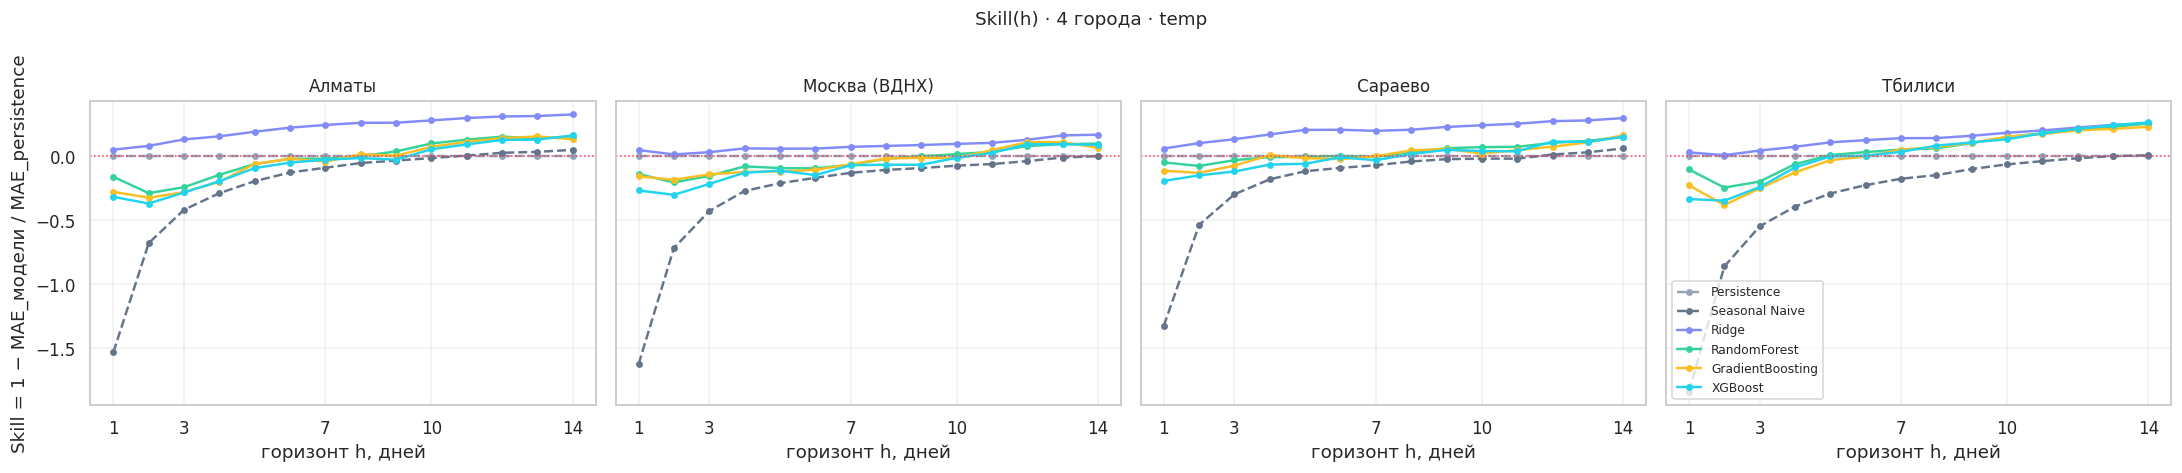

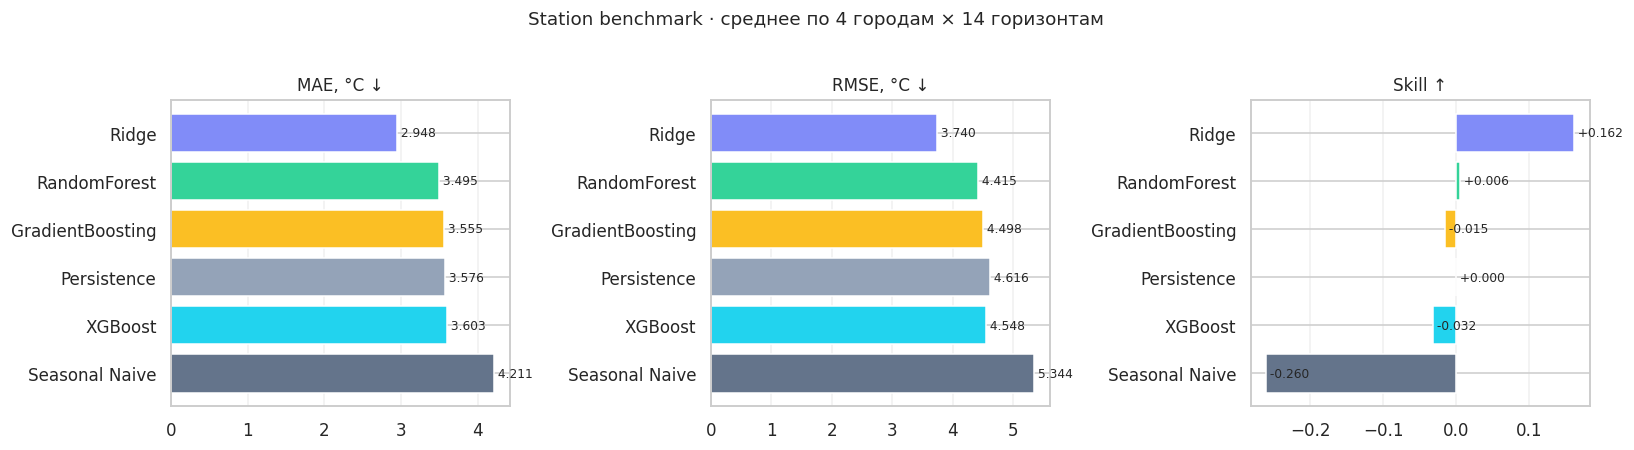

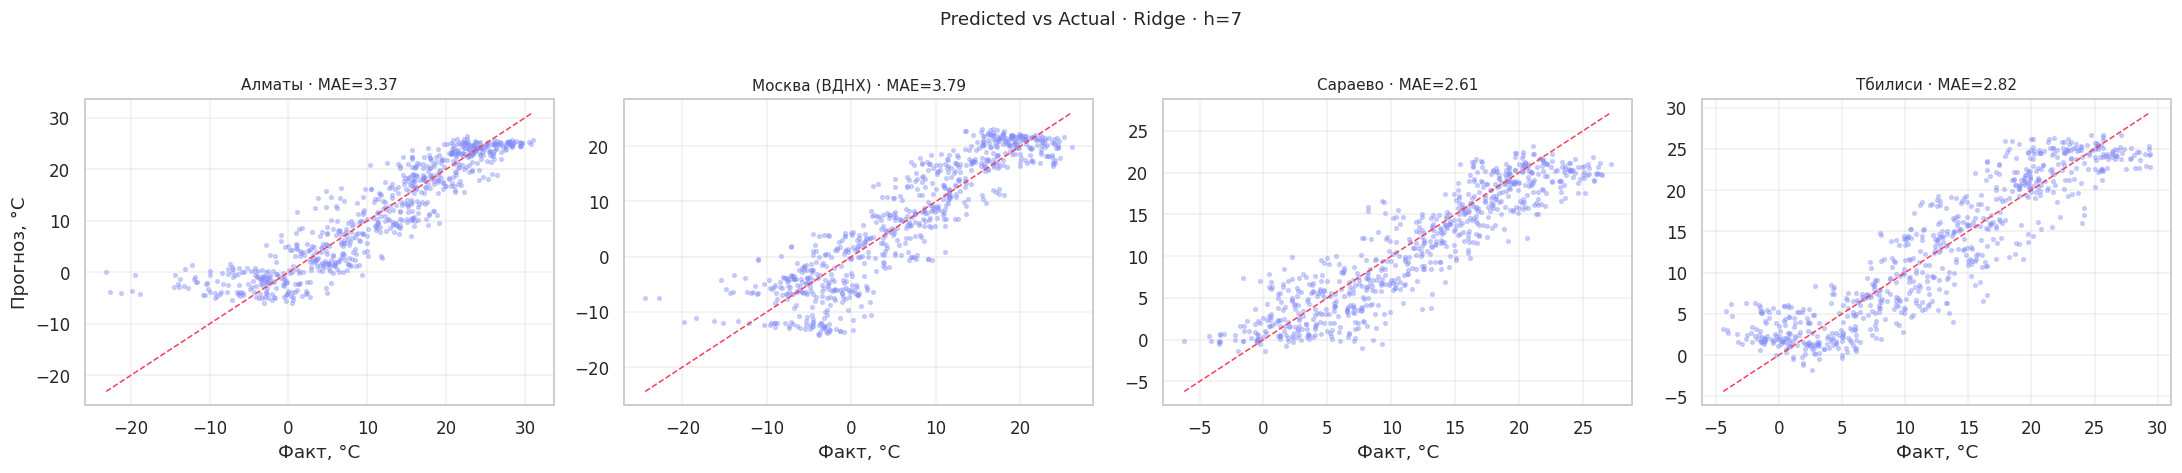

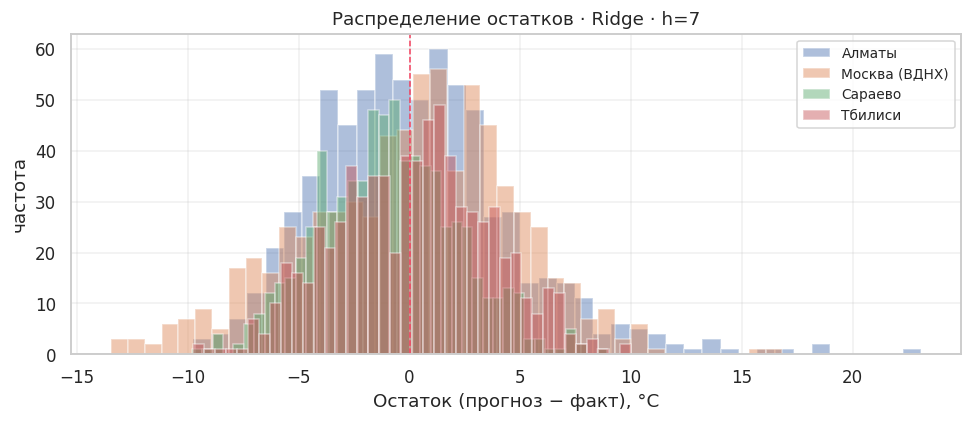

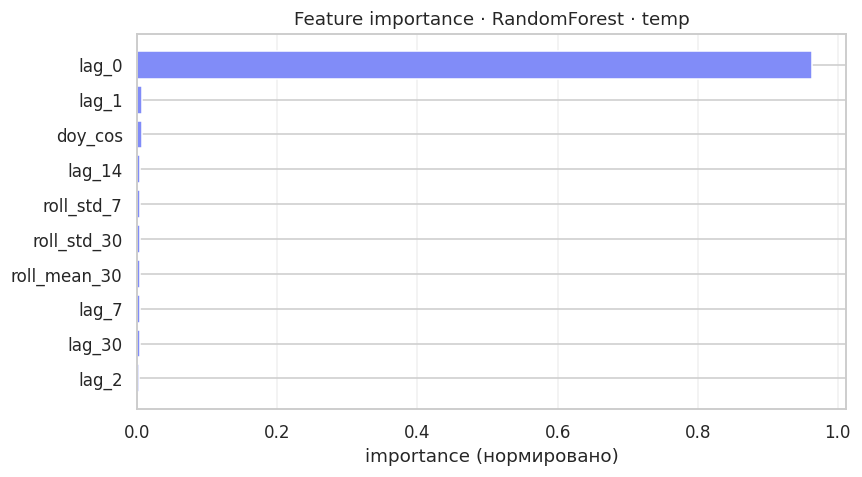


Фигуры сохранены в /app/artifacts/weather/cities/figures


In [8]:
# ============================================================
#  Визуализации station benchmark
#  → artifacts/weather/cities/figures/stations_*.png
# ============================================================
FIG_DIR = ARTIFACTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    "Persistence":      "#94a3b8",
    "Seasonal Naive":   "#64748b",
    "Ridge":            "#818cf8",
    "RandomForest":     "#34d399",
    "GradientBoosting": "#fbbf24",
    "XGBoost":          "#22d3ee",
}

# ---------- 1. Skill(h) по горизонтам для каждой станции ----------
fig, axes = plt.subplots(1, len(CITY_NAMES), figsize=(5 * len(CITY_NAMES), 4.2),
                         sharey=True)
if len(CITY_NAMES) == 1:
    axes = [axes]

for ax, city_name in zip(axes, CITY_NAMES):
    per_model = station_results[city_name]           # {model_name: {h: cell}}
    for m in STATION_MODELS:
        if m not in per_model:
            continue
        model_evals = per_model[m]                   # {h: {points, metrics}}
        skills = []
        for h in STATION_HORIZONS:
            cell = model_evals.get(h) or model_evals.get(str(h))
            if cell is None or "metrics" not in cell:
                skills.append(np.nan)
            else:
                skills.append(cell["metrics"]["skill"])
        ax.plot(STATION_HORIZONS, skills, marker="o", ms=3.5, lw=1.6,
                color=PALETTE.get(m, "gray"),
                linestyle="--" if m in ("Persistence", "Seasonal Naive") else "-",
                label=m)
    ax.axhline(0, color="#f43f5e", lw=1, linestyle=":")
    ax.set_title(CITY_INFO[city_name]["city_ru"], fontsize=11)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks([1, 3, 7, 10, 14])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Skill = 1 − MAE_модели / MAE_persistence")
axes[-1].legend(loc="lower left", fontsize=8)
fig.suptitle("Skill(h) · 4 города · temp", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "stations_skill_by_horizon.png", dpi=110, bbox_inches="tight")
plt.show()


# ---------- 2. Средний MAE по моделям (bar) ----------
rows = []
for m in STATION_MODELS:
    cells = []
    for city_name in CITY_NAMES:
        per_model = station_results[city_name]
        if m not in per_model:
            continue
        model_evals = per_model[m]
        for h in STATION_HORIZONS:
            cell = model_evals.get(h) or model_evals.get(str(h))
            if cell and cell.get("points") and cell.get("metrics"):
                cells.append(cell["metrics"])
    if cells:
        rows.append({
            "model": m,
            "mae":   float(np.mean([c["mae"] for c in cells])),
            "rmse":  float(np.mean([c["rmse"] for c in cells])),
            "skill": float(np.mean([c["skill"] for c in cells])),
        })

df_st = pd.DataFrame(rows).sort_values("mae") if rows else pd.DataFrame()
if not df_st.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric, label in zip(axes, ["mae", "rmse", "skill"],
                                  ["MAE, °C ↓", "RMSE, °C ↓", "Skill ↑"]):
        colors = [PALETTE.get(m, "gray") for m in df_st["model"]]
        ax.barh(df_st["model"], df_st[metric], color=colors)
        ax.invert_yaxis()
        ax.set_title(label, fontsize=11)
        ax.grid(alpha=0.3, axis="x")
        for i, v in enumerate(df_st[metric]):
            ax.text(v, i, f" {v:+.3f}" if metric == "skill" else f" {v:.3f}",
                    va="center", fontsize=8)
    fig.suptitle("Station benchmark · среднее по 4 городам × 14 горизонтам",
                 fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "stations_model_ranking.png", dpi=110, bbox_inches="tight")
    plt.show()


# ---------- 3. Predicted vs Actual: лучшая ML-модель на h=7 ----------
if not df_st.empty:
    best_ml = df_st[df_st["model"] != "Persistence"].iloc[0]["model"]
    h_show = 7

    fig, axes = plt.subplots(1, len(CITY_NAMES), figsize=(5 * len(CITY_NAMES), 4.2),
                             sharex=False, sharey=False)
    if len(CITY_NAMES) == 1:
        axes = [axes]
    for ax, city_name in zip(axes, CITY_NAMES):
        model_evals = station_results[city_name][best_ml]
        cell = model_evals.get(h_show) or model_evals.get(str(h_show))
        pts = cell["points"] if cell else []
        if not pts:
            ax.set_title(f"{CITY_INFO[city_name]['city_ru']} · нет данных")
            continue
        yt = np.array([p["actual"] for p in pts])
        yp = np.array([p["predicted"] for p in pts])
        ax.scatter(yt, yp, s=6, alpha=0.35, color=PALETTE[best_ml])
        lim = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
        ax.plot(lim, lim, "--", color="#f43f5e", lw=1)
        ax.set_title(f"{CITY_INFO[city_name]['city_ru']} · MAE={np.mean(np.abs(yt-yp)):.2f}",
                     fontsize=10)
        ax.set_xlabel("Факт, °C")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("Прогноз, °C")
    fig.suptitle(f"Predicted vs Actual · {best_ml} · h={h_show}", fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "stations_pred_vs_actual.png", dpi=110, bbox_inches="tight")
    plt.show()


# ---------- 4. Распределение остатков (лучшая ML-модель) ----------
if not df_st.empty:
    fig, ax = plt.subplots(figsize=(9, 4))
    for city_name in CITY_NAMES:
        model_evals = station_results[city_name][best_ml]
        cell = model_evals.get(h_show) or model_evals.get(str(h_show))
        pts = cell["points"] if cell else []
        if not pts:
            continue
        resid = np.array([p["predicted"] - p["actual"] for p in pts])
        ax.hist(resid, bins=40, alpha=0.45, label=CITY_INFO[city_name]["city_ru"])
    ax.axvline(0, color="#f43f5e", lw=1, linestyle="--")
    ax.set_xlabel("Остаток (прогноз − факт), °C")
    ax.set_ylabel("частота")
    ax.set_title(f"Распределение остатков · {best_ml} · h={h_show}")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "stations_residuals.png", dpi=110, bbox_inches="tight")
    plt.show()


# ---------- 5. Feature importance ----------
if feature_importance:
    fi = pd.DataFrame(feature_importance).sort_values("value")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(fi["name"], fi["value"], color="#818cf8")
    ax.set_xlabel("importance (нормировано)")
    ax.set_title("Feature importance · RandomForest · temp")
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "stations_feature_importance.png", dpi=110, bbox_inches="tight")
    plt.show()

print(f"\nФигуры сохранены в {FIG_DIR}")

In [9]:
# ============================================================
#  City benchmark: 4 города × 5 переменных × 4 модели   (v2)
#
#  ПРОГНОЗ: 11.12.2023 — 31.12.2023 включительно (21 день).
#  ФАКТ для построения прогноза доступен по 10.12.2023.
#
#  Все модели работают от одного origin: 10.12.2023.
#  Результат сохраняется в artifacts/weather/cities/cities.json.
# ============================================================
import time
from numpy.lib.stride_tricks import sliding_window_view

print("=" * 64)
print("CITY BENCHMARK (v2: origin-based, anomaly + direct)")
print("=" * 64)
print(f"backend: xgboost={HAS_XGB}, sarimax={HAS_SARIMAX}, torch={HAS_TORCH}")

# ------------------------------------------------------------
# ОКНО ПРОГНОЗА: 11–31 декабря включительно
# ------------------------------------------------------------
CITY_N = 66
CITY_PAST = 45
CITY_BACK_START = 45
CITY_ORIGIN = 44

# Метрики на горизонтах 1–7 дней; линия прогноза — на 21 день.
CITY_HORIZONS = list(range(1, 8))

# Определяем функцию ДО первого вызова — исправление NameError.
def _ru_or_en(city_name: str) -> str:
    info = CITY_INFO.get(city_name) or {}
    return info.get("city_ru") or city_name


# ------------------------------------------------------------
# 1) Окно для дашборда
# ------------------------------------------------------------
latest = cities_daily["date"].max()
WINDOW_START = latest - pd.Timedelta(days=CITY_N - 1)

window = cities_daily[
    (cities_daily["date"] >= WINDOW_START) &
    (cities_daily["date"] <= latest)
].copy()

assert window["date"].nunique() == CITY_N, (
    f"Ожидалось {CITY_N} дней, найдено {window['date'].nunique()}"
)

window_dates = [
    pd.Timestamp(d)
    for d in sorted(window["date"].unique())
]

assert len(window_dates) == 66
assert window_dates[0].strftime("%Y-%m-%d") == "2023-10-27", (
    f"Неожиданное начало окна: {window_dates[0].date()}"
)
assert window_dates[CITY_ORIGIN].strftime("%Y-%m-%d") == "2023-12-10", (
    f"Неожиданный origin: {window_dates[CITY_ORIGIN].date()}"
)
assert window_dates[CITY_BACK_START].strftime("%Y-%m-%d") == "2023-12-11", (
    f"Неожиданное начало прогноза: {window_dates[CITY_BACK_START].date()}"
)
assert window_dates[-1].strftime("%Y-%m-%d") == "2023-12-31", (
    f"Неожиданный конец окна: {window_dates[-1].date()}"
)
assert CITY_PAST == CITY_BACK_START == CITY_ORIGIN + 1

print(
    f"Окно показа   : {window_dates[0].date()} "
    f"→ {window_dates[-1].date()} ({CITY_N} дней)"
)
print(f"Последний факт: {window_dates[CITY_ORIGIN].date()}")
print(f"Начало прогноза: {window_dates[CITY_BACK_START].date()}")
print(f"Конец прогноза : {window_dates[-1].date()}")
print(f"Горизонт       : {CITY_N - CITY_BACK_START} дней")
print(
    f"Окно метрик    : {TEST_START.date()} → {TEST_END.date()} "
    f"({int(((cities_daily['date'] >= TEST_START) & (cities_daily['date'] <= TEST_END)).sum() // len(CITY_NAMES))} дней)"
)


# ------------------------------------------------------------
# 2) Константы моделей
# ------------------------------------------------------------
H_MAX = CITY_N - CITY_ORIGIN - 1
assert H_MAX == 21, f"Ожидался горизонт 21 день, получено {H_MAX}"
assert H_MAX >= max(CITY_HORIZONS)

ALL_H = list(range(1, H_MAX + 1))

ANOM_LAGS = [0, 1, 2, 3, 5, 7, 10, 14, 21, 30]
ANOM_ROLL = [3, 7, 14, 30]
ANOM_STD = [7, 30]
MIN_HIST = 30

XGB_TRAIN_H = sorted({
    h for h in (set(range(1, 8)) | {9, 11, 14, 17, 21, H_MAX})
    if h <= H_MAX
})

LSTM_LOOKBACK = 30
LSTM_HIDDEN = 48
LSTM_EPOCHS = 20
LSTM_BATCH = 256

SARIMAX_ORDER = (2, 0, 1)
SARIMAX_WINDOW = 90


# ------------------------------------------------------------
# Утилиты: ряды, климатология, аномалии, признаки
# ------------------------------------------------------------
def _get_series(city_name: str, var_src: str):
    sub = (
        cities_daily.loc[
            cities_daily["city"] == city_name,
            ["date", var_src]
        ]
        .reset_index(drop=True)
    )

    y = (
        pd.Series(sub[var_src].astype(float).values)
        .interpolate(limit_direction="both")
        .values
    )

    return pd.DatetimeIndex(sub["date"]), y


def _climatology(
    dates_train,
    y_train,
    smooth: int = 21
) -> np.ndarray:
    """Климатология по дню года (366 значений), сглаженная по кругу."""
    doy = pd.DatetimeIndex(dates_train).dayofyear.values

    clim = (
        pd.Series(y_train)
        .groupby(doy)
        .mean()
        .reindex(range(1, 367))
        .interpolate(limit_direction="both")
        .values
    )

    pad = smooth
    ext = np.concatenate([clim[-pad:], clim, clim[:pad]])

    sm = (
        pd.Series(ext)
        .rolling(smooth, center=True, min_periods=1)
        .mean()
        .values
    )

    return sm[pad:-pad]


def _clim_at(clim: np.ndarray, dates) -> np.ndarray:
    return clim[pd.DatetimeIndex(dates).dayofyear.values - 1]


def _origin_features(
    a: np.ndarray,
    dates: pd.DatetimeIndex,
    clim_o: np.ndarray
) -> pd.DataFrame:
    """Признаки на день origin t: используются только данные до t."""
    s = pd.Series(a)
    cols = {}

    for l in ANOM_LAGS:
        cols[f"a_lag_{l}"] = s.shift(l).values

    for w in ANOM_ROLL:
        cols[f"a_mean_{w}"] = s.rolling(w).mean().values

    for w in ANOM_STD:
        cols[f"a_std_{w}"] = s.rolling(w).std().values

    doy = dates.dayofyear.values
    cols["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    cols["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    cols["clim_o"] = clim_o

    return pd.DataFrame(cols)


def _stack_X(
    Xb: np.ndarray,
    dates: pd.DatetimeIndex,
    clim: np.ndarray,
    idx: np.ndarray,
    h: int
) -> np.ndarray:
    """Признаки origin + горизонт + сезонность целевой даты."""
    tgt_doy = (
        dates[idx] + pd.Timedelta(days=h)
    ).dayofyear.values

    extra = np.column_stack([
        np.full(len(idx), float(h)),
        np.sin(2 * np.pi * tgt_doy / 365.25),
        np.cos(2 * np.pi * tgt_doy / 365.25),
        clim[tgt_doy - 1],
    ])

    return np.hstack([Xb[idx], extra])


def _clim_target_matrix(
    dates: pd.DatetimeIndex,
    clim: np.ndarray,
    origins: np.ndarray
) -> np.ndarray:
    out = np.empty((len(origins), H_MAX))

    for h in ALL_H:
        tgt_doy = (
            dates[origins] + pd.Timedelta(days=h)
        ).dayofyear.values

        out[:, h - 1] = clim[tgt_doy - 1]

    return out


def _postprocess(var_src: str, pred: np.ndarray) -> np.ndarray:
    if var_src in ("precipitation", "wind"):
        return np.maximum(pred, 0.0)

    if var_src == "humidity":
        return np.clip(pred, 0.0, 100.0)

    return pred


# ------------------------------------------------------------
# Модели: predict(origins) → прогноз аномалии [n, H_MAX]
# ------------------------------------------------------------
def _fit_gbm(X: np.ndarray, y: np.ndarray):
    if HAS_XGB:
        return xgb.XGBRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=20,
            tree_method="hist",
            n_jobs=-1,
            random_state=42,
            verbosity=0,
        ).fit(X, y)

    from sklearn.ensemble import HistGradientBoostingRegressor

    return HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_depth=5,
        min_samples_leaf=40,
        random_state=42,
    ).fit(X, y)


def _build_xgb(ctx):
    """Ridge на каждом горизонте + GBM на остатках."""
    Xb = ctx["Xb"]
    a = ctx["a"]
    dates = ctx["dates"]
    clim = ctx["clim"]
    n_train = ctx["n_train"]

    fin = np.isfinite(Xb).all(axis=1)

    scaler = StandardScaler().fit(
        Xb[fin & (np.arange(len(Xb)) < n_train)]
    )

    Xz = scaler.transform(np.nan_to_num(Xb))
    ridges = {}

    for h in ALL_H:
        idx = np.arange(MIN_HIST, n_train - h)
        ridges[h] = Ridge(alpha=10.0).fit(
            Xz[idx],
            a[idx + h]
        )

    Xs, ys = [], []

    for h in XGB_TRAIN_H:
        idx = np.arange(MIN_HIST, n_train - h)

        X = _stack_X(Xb, dates, clim, idx, h)
        y = a[idx + h] - ridges[h].predict(Xz[idx])

        ok = np.isfinite(X).all(axis=1) & np.isfinite(y)

        Xs.append(X[ok])
        ys.append(y[ok])

    model = _fit_gbm(
        np.vstack(Xs),
        np.concatenate(ys)
    )

    def predict(origins):
        origins = np.asarray(origins)
        out = np.empty((len(origins), H_MAX))

        for h in ALL_H:
            out[:, h - 1] = (
                ridges[h].predict(Xz[origins])
                + model.predict(
                    _stack_X(Xb, dates, clim, origins, h)
                )
            )

        return out

    return predict


if HAS_TORCH:
    class _LSTMNet(nn.Module):
        """Direct multi-output: 30 дней на входе, H_MAX шагов на выходе."""

        def __init__(
            self,
            horizon: int,
            hidden: int = LSTM_HIDDEN
        ):
            super().__init__()

            self.lstm = nn.LSTM(
                3,
                hidden,
                batch_first=True
            )

            self.head = nn.Sequential(
                nn.Linear(hidden, hidden),
                nn.ReLU(),
                nn.Linear(hidden, horizon)
            )

        def forward(self, x):
            o, _ = self.lstm(x)
            return self.head(o[:, -1, :])


def _build_lstm(ctx):
    a = ctx["a"]
    dates = ctx["dates"]
    n_train = ctx["n_train"]

    LB = LSTM_LOOKBACK
    H = H_MAX

    sd_a = float(np.std(a[:n_train])) + 1e-9
    az = a / sd_a
    doy = dates.dayofyear.values

    chan = np.stack([
        az,
        np.sin(2 * np.pi * doy / 365.25),
        np.cos(2 * np.pi * doy / 365.25),
    ], axis=1).astype(np.float32)

    wins = sliding_window_view(
        chan,
        LB,
        axis=0
    )

    wins = np.ascontiguousarray(
        wins.transpose(0, 2, 1)
    )

    tr_orig = np.arange(
        LB - 1,
        n_train - H
    )

    Y = np.stack(
        [az[tr_orig + h] for h in ALL_H],
        axis=1
    ).astype(np.float32)

    Xtr = torch.from_numpy(
        wins[tr_orig - (LB - 1)]
    )

    Ytr = torch.from_numpy(Y)

    torch.manual_seed(42)

    net = _LSTMNet(H)

    opt = torch.optim.AdamW(
        net.parameters(),
        lr=3e-3,
        weight_decay=1e-4
    )

    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt,
        T_max=LSTM_EPOCHS
    )

    loss_fn = nn.MSELoss()
    n = len(Xtr)

    for _ in range(LSTM_EPOCHS):
        net.train()
        perm = torch.randperm(n)

        for b in range(0, n, LSTM_BATCH):
            ib = perm[b:b + LSTM_BATCH]

            opt.zero_grad()
            loss = loss_fn(net(Xtr[ib]), Ytr[ib])
            loss.backward()
            opt.step()

        sched.step()

    net.eval()

    def predict(origins):
        with torch.no_grad():
            xb = torch.from_numpy(
                wins[np.asarray(origins) - (LB - 1)]
            )

            return (
                net(xb).numpy().astype(float) * sd_a
            )

    return predict


def _build_sarimax(ctx):
    a = ctx["a"]
    n_train = ctx["n_train"]

    res = SARIMAX(
        a[:n_train][-3000:],
        order=SARIMAX_ORDER,
        enforce_stationarity=True,
        enforce_invertibility=True
    ).fit(disp=False)

    params = np.asarray(res.params)
    decay = np.exp(
        -np.arange(1, H_MAX + 1) / 3.0
    )

    def predict(origins):
        out = np.empty((len(origins), H_MAX))

        for k, t in enumerate(origins):
            w = a[
                max(0, t - SARIMAX_WINDOW + 1):t + 1
            ]

            try:
                m = SARIMAX(
                    w,
                    order=SARIMAX_ORDER,
                    enforce_stationarity=True,
                    enforce_invertibility=True
                )

                fc = np.asarray(
                    m.filter(params).forecast(steps=H_MAX),
                    dtype=float
                )

                if not np.all(np.isfinite(fc)):
                    raise ValueError("NaN/Inf")

            except Exception:
                fc = a[t] * decay

            out[k] = fc

        return out

    return predict


ANOM_BUILDERS = {
    "XGBoost": _build_xgb,
    "LSTM": _build_lstm,
    "SARIMAX": _build_sarimax
}


def _model_matrix(
    model_name: str,
    ctx
) -> np.ndarray:
    """Абсолютный прогноз [n_origins, H_MAX]."""
    o = ctx["origins"]
    y = ctx["y"]

    if model_name == "Persistence":
        pred = np.repeat(
            y[o][:, None],
            H_MAX,
            axis=1
        )
    else:
        pred_a = ANOM_BUILDERS[model_name](ctx)(o)
        pred = ctx["clim_tgt"] + pred_a

    return _postprocess(ctx["var_src"], pred)


# ------------------------------------------------------------
# Оценка: матрица прогнозов → метрики, leadMae, residual SD
# ------------------------------------------------------------
def _eval_matrix(
    y,
    origins,
    n_end,
    pred,
    base_mae_by_h=None
):
    base_mae_by_h = base_mae_by_h or {}
    res = {}

    for h in ALL_H:
        ok = (origins + h) < n_end

        yt = y[origins[ok] + h]
        yp = pred[ok, h - 1]

        res[h] = {
            "metrics": compute_metrics(
                yt,
                yp,
                baseline_mae=base_mae_by_h.get(h)
            ),
            "resid_std": float(
                np.std(yp - yt)
            ) if len(yt) else 0.0,
            "n": int(len(yt)),
        }

    return res


# ------------------------------------------------------------
# 3) Прогон по всем городам и переменным
# ------------------------------------------------------------
city_models_data: dict[str, dict] = {}
city_feature_importance: dict[str, dict] = {}

t_start = time.time()

for city_name in CITY_NAMES:
    print(f"\n[{city_name}]")

    vars_out = {}
    city_feature_importance[city_name] = {}

    for city_key, src_key in CITY_VAR_MAP.items():
        dates, y = _get_series(city_name, src_key)

        n_train = int((dates <= TRAIN_END).sum())
        n_end = int((dates <= TEST_END).sum())

        origins = np.arange(
            n_train - 1,
            n_end - 1
        )

        # Климатология и аномалии для backtest — на train.
        clim = _climatology(
            dates[:n_train],
            y[:n_train]
        )

        clim_all = _clim_at(clim, dates)
        a = y - clim_all

        feats = _origin_features(
            a,
            dates,
            clim_all
        )

        origin_cols = list(feats.columns)
        Xb = feats.values.astype(float)

        ctx = dict(
            var_src=src_key,
            y=y,
            a=a,
            dates=dates,
            clim=clim,
            Xb=Xb,
            n_train=n_train,
            origins=origins,
            clim_tgt=_clim_target_matrix(
                dates,
                clim,
                origins
            ),
        )

        # Индексы окна показа и origin.
        idx_w = dates.get_indexer(window_dates)

        assert (idx_w >= 0).all(), (
            "В окне показа есть даты, которых нет в ряду"
        )

        disp_idx = int(idx_w[CITY_ORIGIN])
        disp_pos = disp_idx - int(origins[0])

        assert 0 <= disp_pos < len(origins), (
            "Origin окна вне тестового периода"
        )

        # Display-модель обучается на всех доступных фактах до origin.
        # Данные после origin не участвуют в построении прогноза.
        n_train_display = disp_idx + 1

        clim_display = _climatology(
            dates[:n_train_display],
            y[:n_train_display]
        )

        clim_all_display = _clim_at(
            clim_display,
            dates
        )

        a_display = y - clim_all_display

        feats_display = _origin_features(
            a_display,
            dates,
            clim_all_display
        )

        Xb_display = feats_display.values.astype(float)
        display_origin = np.array([disp_idx], dtype=int)

        ctx_display = dict(
            var_src=src_key,
            y=y,
            a=a_display,
            dates=dates,
            clim=clim_display,
            Xb=Xb_display,
            n_train=n_train_display,
            origins=display_origin,
            clim_tgt=_clim_target_matrix(
                dates,
                clim_display,
                display_origin
            ),
        )

        var_block = {
            "actual": [float(v) for v in y[idx_w]],
            "models": [],
            "leadMae": {},
            "metricsByHorizon": {},
        }

        # Persistence — baseline для skill.
        pers_pred = _model_matrix(
            "Persistence",
            ctx
        )

        pers_ev = _eval_matrix(
            y,
            origins,
            n_end,
            pers_pred
        )

        pers_mae_by_h = {
            h: pers_ev[h]["metrics"]["mae"]
            for h in ALL_H
        }

        for mname in CITY_MODELS:
            if mname == "Persistence":
                pred, ev = pers_pred, pers_ev

            else:
                try:
                    pred = _model_matrix(
                        mname,
                        ctx
                    )

                    if not np.all(np.isfinite(pred)):
                        raise ValueError("NaN/Inf в прогнозе")

                except Exception as e:
                    print(
                        f"  [{city_name}/{src_key}/{mname}] "
                        f"FAIL → fallback Persistence: {e}"
                    )

                    pred = pers_pred

                ev = _eval_matrix(
                    y,
                    origins,
                    n_end,
                    pred,
                    pers_mae_by_h
                )

            # Прогноз от origin на h=1..21.
            # Метрики вычисляются отдельно на историческом тестовом периоде.
            try:
                display_row = _model_matrix(
                    mname,
                    ctx_display
                )[0]

                if not np.all(np.isfinite(display_row)):
                    raise ValueError("NaN/Inf в display-прогнозе")

            except Exception as e:
                print(
                    f"  [{city_name}/{src_key}/{mname}] "
                    f"DISPLAY FAIL → fallback Persistence: {e}"
                )

                display_row = _model_matrix(
                    "Persistence",
                    ctx_display
                )[0]

            forecast = [None] * CITY_N
            sd_out = [None] * CITY_N

            for j in range(CITY_BACK_START, CITY_N):
                h = j - CITY_ORIGIN

                forecast[j] = float(
                    display_row[h - 1]
                )

                sd_out[j] = round(
                    float(ev[h]["resid_std"]),
                    4
                )

            block = {
                "name": mname,
                "forecast": forecast,
                "sd": sd_out,
                "displayFitEnd": dates[disp_idx].strftime("%Y-%m-%d"),
            }

            # 1-step метрики на полном тестовом периоде.
            block["metrics"] = {
                k: round(float(v), 5)
                for k, v in ev[1]["metrics"].items()
            }

            block["metricsWindow"] = {
                "start": TEST_START.strftime("%Y-%m-%d"),
                "end": TEST_END.strftime("%Y-%m-%d"),
                "n": int(ev[1]["n"]),
            }

            # Метрики для горизонтов 1–7 дней.
            var_block["leadMae"][mname] = [
                round(float(ev[h]["metrics"]["mae"]), 4)
                for h in CITY_HORIZONS
            ]

            var_block["metricsByHorizon"][mname] = {
                str(h): {
                    **{
                        k: round(float(v), 5)
                        for k, v in ev[h]["metrics"].items()
                    },
                    "n": ev[h]["n"],
                    "residStd": round(
                        float(ev[h]["resid_std"]),
                        5
                    ),
                }
                for h in CITY_HORIZONS
            }

            var_block["models"].append(block)

        vars_out[city_key] = var_block

        # Feature importance: RandomForest для горизонта h=3.
        try:
            idx = np.arange(
                MIN_HIST,
                n_train - 3
            )

            X_fi = Xb[idx]
            y_fi = a[idx + 3]

            ok = (
                np.isfinite(X_fi).all(axis=1)
                & np.isfinite(y_fi)
            )

            rf = RandomForestRegressor(
                n_estimators=60,
                max_depth=10,
                min_samples_leaf=20,
                n_jobs=-1,
                random_state=42
            ).fit(
                X_fi[ok],
                y_fi[ok]
            )

            pairs = sorted(
                zip(origin_cols, rf.feature_importances_),
                key=lambda kv: -kv[1]
            )[:10]

            total = sum(v for _, v in pairs) or 1.0

            city_feature_importance[city_name][city_key] = [
                {
                    "name": k,
                    "value": round(float(v / total), 4)
                }
                for k, v in pairs
            ]

        except Exception as e:
            print(
                f"  [FI/{city_name}/{city_key}] fail: {e}"
            )

        # Краткий лог по каждой переменной.
        maes = {
            m["name"]: m["metrics"]["mae"]
            for m in var_block["models"]
        }

        mae_str = "  ".join(
            f"{k}={v:.2f}"
            for k, v in maes.items()
        )

        # MAE на прогнозном участке 11–31 декабря.
        act = np.array(var_block["actual"])
        disp = {}

        for m in var_block["models"]:
            fc = np.array([
                v if v is not None else np.nan
                for v in m["forecast"]
            ], dtype=float)

            msk = ~np.isnan(fc)

            disp[m["name"]] = (
                float(np.mean(np.abs(fc[msk] - act[msk])))
                if msk.any()
                else float("nan")
            )

        disp_str = "  ".join(
            f"{k}={v:.2f}"
            for k, v in disp.items()
        )

        lead_str = "  ".join(
            f"{m['name']}:h7={var_block['leadMae'][m['name']][-1]:.2f}"
            for m in var_block["models"]
        )

        print(
            f"   {city_key:5s} ok  |  1-step MAE: {mae_str}"
        )

        print(
            f"                |  MAE на графике (h=1..{H_MAX}): {disp_str}"
        )

        print(
            f"                |  leadMAE: {lead_str}"
        )

    city_models_data[city_name] = {
        "name": _ru_or_en(city_name),
        "nameEn": city_name,
        "dates": [
            d.strftime("%Y-%m-%d")
            for d in window_dates
        ],
        "vars": vars_out,
    }

print(
    f"\nВремя расчёта: {(time.time() - t_start) / 60:.1f} мин"
)


# ------------------------------------------------------------
# 4) Сборка cities.json
# ------------------------------------------------------------
cities_artifact = {
    "source": "open-meteo archive · real data",
    "generatedAt": datetime.now().isoformat(),
    "dates": [
        d.strftime("%Y-%m-%d")
        for d in window_dates
    ],

    # 45 дней до начала прогноза и 21 день прогноза.
    "nPast": CITY_PAST,
    "backStart": CITY_BACK_START,
    "origin": CITY_ORIGIN,
    "forecastDays": CITY_N - CITY_PAST,

    "horizons": CITY_HORIZONS,

    "variables": [
        {"key": k, "label": v["label"], "unit": v["unit"], "icon": v["icon"]}
        for k, v in [
            ("temp", {"label": "Температура", "unit": "°C", "icon": "🌡️"}),
            ("hum", {"label": "Влажность", "unit": "%", "icon": "💧"}),
            ("rain", {"label": "Осадки", "unit": "мм", "icon": "🌧️"}),
            ("wind", {"label": "Ветер", "unit": "м/с", "icon": "💨"}),
            ("pres", {"label": "Давление", "unit": "гПа", "icon": "🧭"}),
        ]
    ],

    "modelNames": list(CITY_MODELS),

    "cities": [
        {
            "name": _ru_or_en(cn),
            "nameEn": cn,
            "dates": city_models_data[cn]["dates"],
            "vars": city_models_data[cn]["vars"],
        }
        for cn in CITY_NAMES
    ],

    "featureImportance": city_feature_importance,

    "metricsSource": {
        "period": (
            f"{TEST_START.strftime('%Y-%m-%d')} "
            f"→ {TEST_END.strftime('%Y-%m-%d')}"
        ),
        "n_days": int(
            (
                (cities_daily["date"] >= TEST_START)
                & (cities_daily["date"] <= TEST_END)
            ).sum() // len(CITY_NAMES)
        ),
        "protocol": (
            "Все модели обучены на данных до даты origin. "
            "Прогноз строится на аномалиях y − климатология(doy), "
            "а затем к прогнозу аномалии добавляется климатология "
            "целевой даты. XGBoost — Ridge на каждом горизонте "
            "+ бустинг на остатках с признаком горизонта; "
            "LSTM — direct multi-output; SARIMAX — ARMA(2,0,1) "
            "на аномалиях. Метрики leadMae/metricsByHorizon рассчитаны "
            "на горизонтах 1–7 дней. Прогноз для дашборда строится "
            "от origin 2023-12-10 на период 2023-12-11—2023-12-31."
        ),
    },
}


# ------------------------------------------------------------
# 5) Санитайз NaN/Inf и запись
# ------------------------------------------------------------
def _clean(o):
    import math

    if isinstance(o, float):
        return o if math.isfinite(o) else None

    if isinstance(o, dict):
        return {
            k: _clean(v)
            for k, v in o.items()
        }

    if isinstance(o, list):
        return [
            _clean(v)
            for v in o
        ]

    return o


cities_artifact = _clean(cities_artifact)

out_path = ARTIFACTS_DIR / "cities.json"

out_path.write_text(
    json.dumps(
        cities_artifact,
        indent=2,
        ensure_ascii=False
    )
)

print(
    f"\nsaved → {out_path} "
    f"({out_path.stat().st_size / 1024:.1f} KB)"
)
print("\nГотово.")

CITY BENCHMARK (v2: origin-based, anomaly + direct)
backend: xgboost=True, sarimax=True, torch=True
Окно показа   : 2023-10-27 → 2023-12-31 (66 дней)
Последний факт: 2023-12-10
Начало прогноза: 2023-12-11
Конец прогноза : 2023-12-31
Горизонт       : 21 дней
Окно метрик    : 2022-01-01 → 2023-12-31 (730 дней)

[Almaty]
   temp  ok  |  1-step MAE: Persistence=1.95  SARIMAX=1.95  XGBoost=1.93  LSTM=1.95
                |  MAE на графике (h=1..21): Persistence=6.76  SARIMAX=4.90  XGBoost=5.35  LSTM=5.17
                |  leadMAE: Persistence:h7=4.45  SARIMAX:h7=3.91  XGBoost:h7=3.50  LSTM:h7=3.56
   hum   ok  |  1-step MAE: Persistence=9.38  SARIMAX=9.61  XGBoost=9.20  LSTM=9.19
                |  MAE на графике (h=1..21): Persistence=18.71  SARIMAX=14.67  XGBoost=12.10  LSTM=14.81
                |  leadMAE: Persistence:h7=15.39  SARIMAX:h7=16.29  XGBoost:h7=12.77  LSTM:h7=12.73
   rain  ok  |  1-step MAE: Persistence=2.47  SARIMAX=2.57  XGBoost=2.45  LSTM=2.36
                |  MAE на 

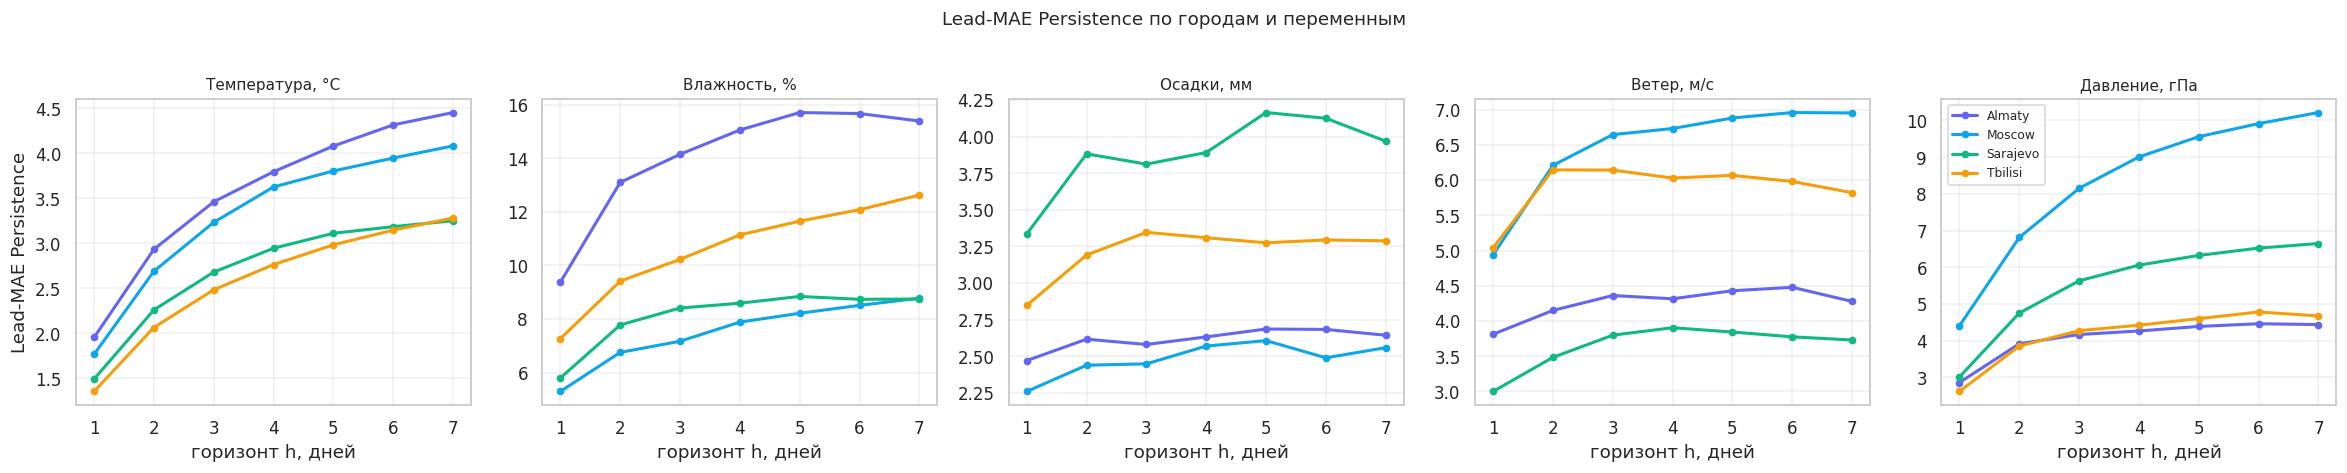

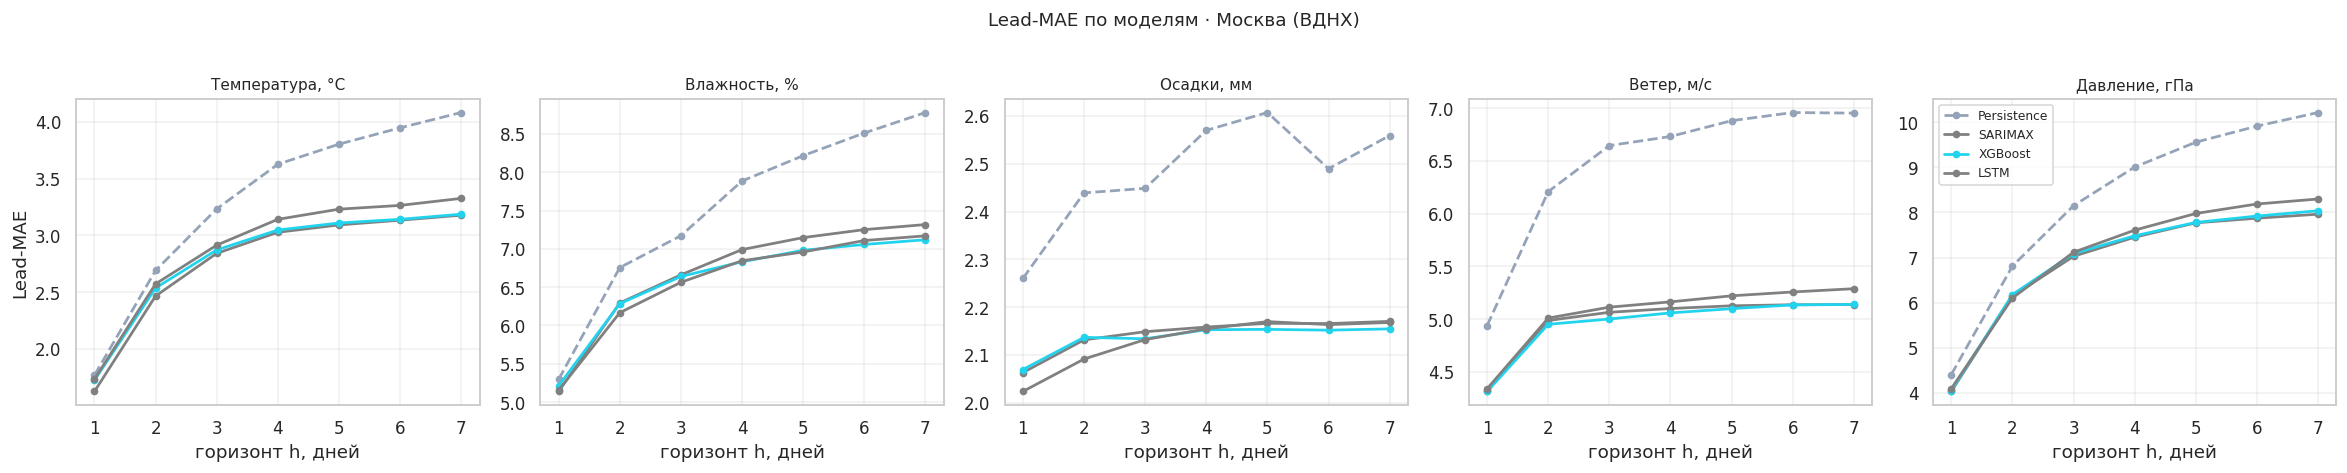

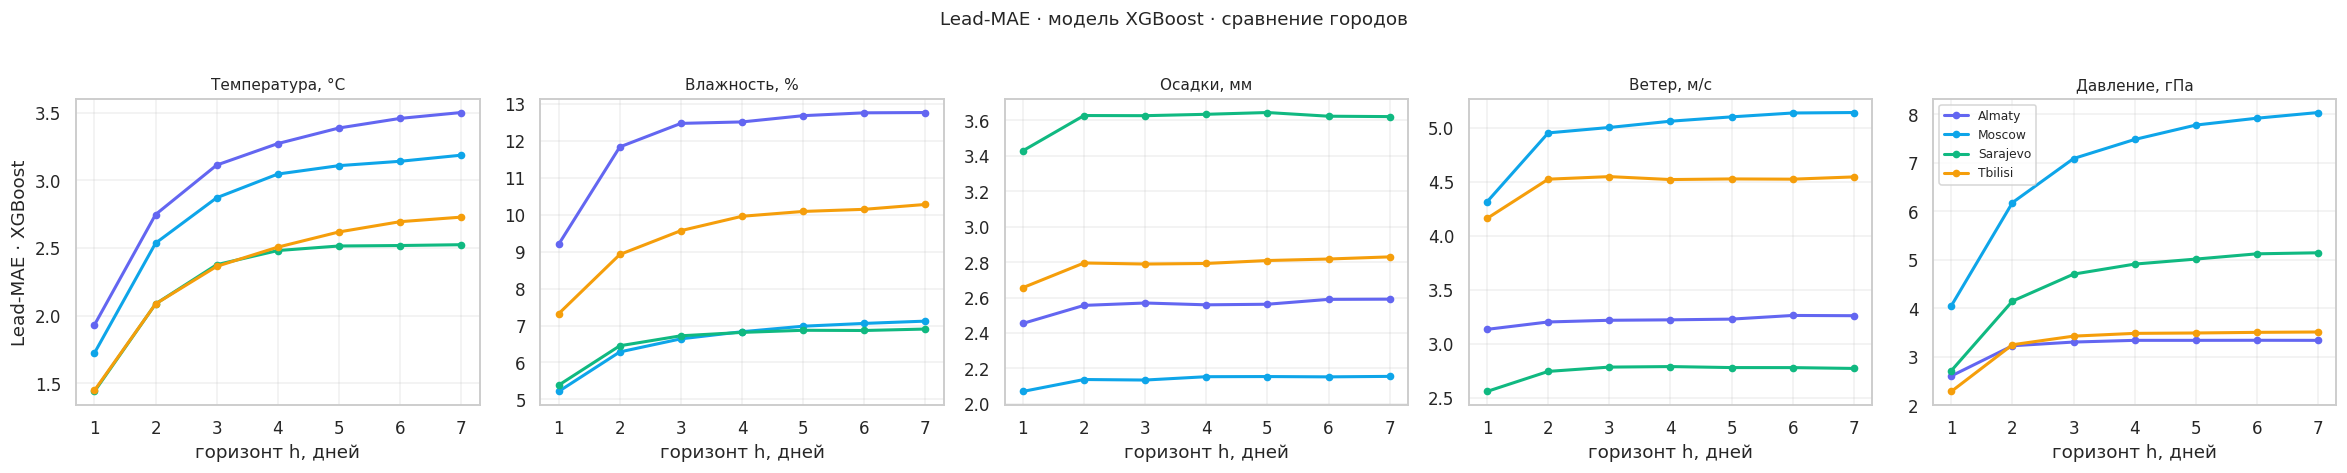

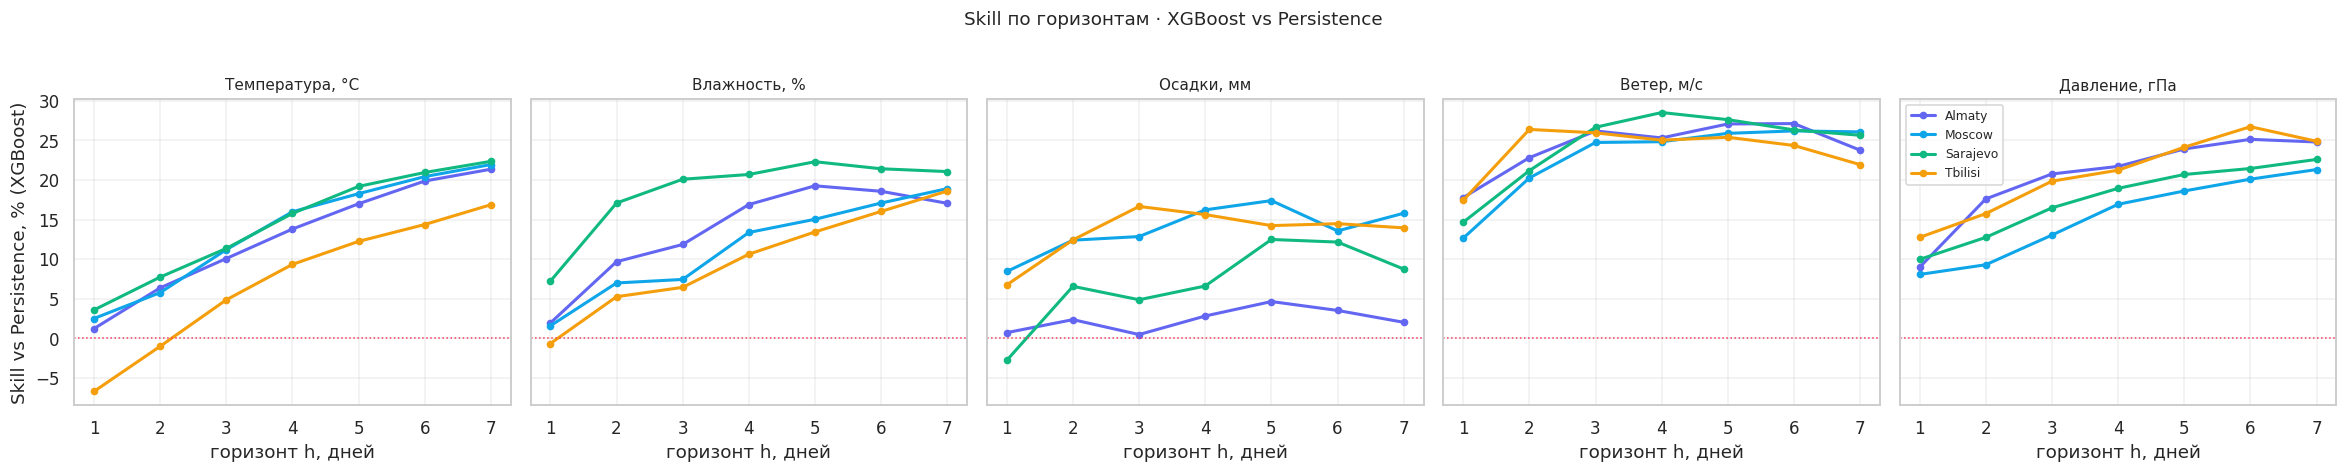

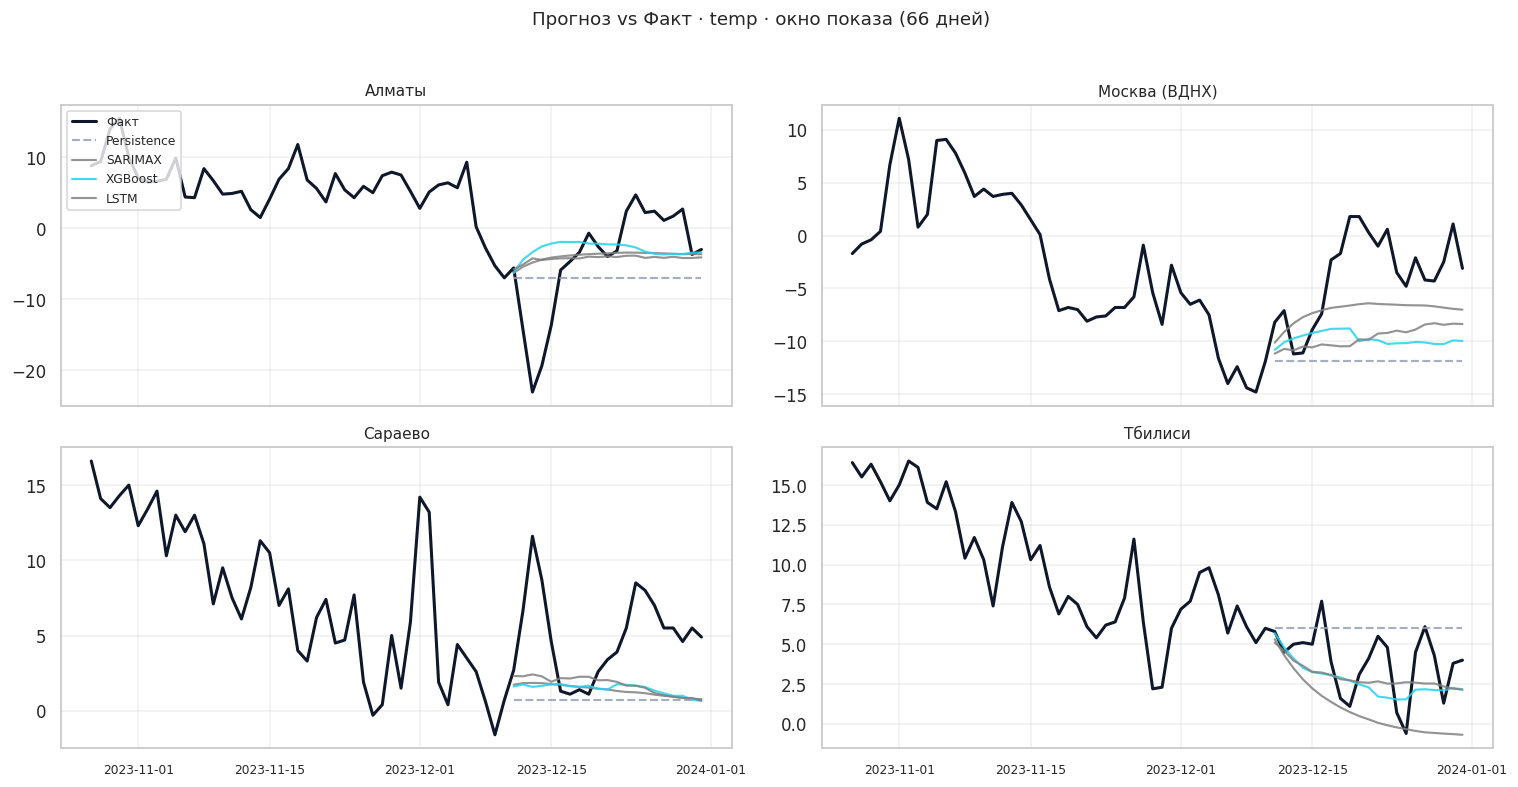


Фигуры сохранены в /app/artifacts/weather/cities/figures


In [10]:
# ============================================================
#  Визуализации city benchmark
#  → artifacts/weather/cities/figures/city_*.png
#
#  Стиль: одна панель = одна переменная, 4 линии = 4 города.
#
#  FIX (OSError [Errno 22] Invalid argument при savefig):
#   * _savefig_safe() — обёртка над fig.savefig, которая:
#       - гарантирует существование parent-директории;
#       - удаляет по целевому пути всё, что не является обычным
#         файлом (директория, симлинк, сокет, fifo) — именно такое
#         состояние даёт EINVAL в open(path, 'w+b') внутри PIL;
#       - сохраняет через tmp-файл в той же директории и делает
#         atomic os.replace → не оставляет полу-файлов;
#       - передаёт в savefig str(path), а не Path (обход бага
#         PIL + pathlib на некоторых volume-mount FS).
#   * plt.close(fig) после каждой фигуры — в inline-бэкенде без
#     close фигуры копятся, canvas загрязняется и последний
#     savefig может упасть.
#   * Сетка subplots для 10-й фигуры теперь считается от
#     len(CITY_NAMES), а не хардкод 2×2.
# ============================================================
import os
import shutil
import tempfile
from pathlib import Path

FIG_DIR = Path(ARTIFACTS_DIR) / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert FIG_DIR.is_dir(), f"FIG_DIR exists but is not a directory: {FIG_DIR}"


def _savefig_safe(fig, path, **kwargs):
    """Надёжное сохранение: чистит битый target, atomic move, str(path)."""
    path = Path(path)
    parent = path.parent
    parent.mkdir(parents=True, exist_ok=True)
    assert parent.is_dir(), f"parent exists but is not a directory: {parent}"

    # 1) Если по целевому пути лежит что-то нерегулярное
    #    (директория, битый симлинк, сокет, fifo) — удаляем.
    #    Это лечит EINVAL.
    try:
        if path.is_symlink():
            path.unlink()
        elif path.exists() and not path.is_file():
            if path.is_dir():
                shutil.rmtree(path)
            else:
                path.unlink()
    except FileNotFoundError:
        pass

    # 2) Best-effort unlink обычного файла — чтобы os.replace
    #    не спотыкался на immutable/read-only остатках.
    try:
        if path.is_file():
            path.unlink()
    except OSError:
        pass

    # 3) Пишем в tmp в той же директории, затем atomic rename.
    fd, tmp_name = tempfile.mkstemp(prefix=".tmp_", suffix=path.suffix,
                                    dir=str(parent))
    os.close(fd)
    try:
        fig.savefig(tmp_name, **kwargs)
        os.replace(tmp_name, str(path))
    except Exception:
        try:
            os.remove(tmp_name)
        except OSError:
            pass
        raise


VAR_LABELS = {"temp": "Температура, °C", "hum": "Влажность, %",
              "rain": "Осадки, мм", "wind": "Ветер, м/с",
              "pres": "Давление, гПа"}

CITY_COLORS = {
    "Almaty":   "#6366f1",
    "Moscow":   "#0ea5e9",
    "Sarajevo": "#10b981",
    "Tbilisi":  "#f59e0b",
}

# Общий PALETTE для моделей (если ещё не определён)
if "PALETTE" not in globals():
    PALETTE = {
        "Persistence":      "#94a3b8",
        "Seasonal Naive":   "#64748b",
        "Ridge":            "#818cf8",
        "RandomForest":     "#34d399",
        "GradientBoosting": "#fbbf24",
        "XGBoost":          "#22d3ee",
        "SARIMAX":          "#a78bfa",
        "LSTM":             "#f472b6",
    }


# ---------- 6. Lead-MAE по горизонтам: 5 панелей, 4 линии = 4 города ----------
fig, axes = plt.subplots(1, len(CITY_VAR_MAP),
                         figsize=(4.3 * len(CITY_VAR_MAP), 4.2),
                         sharey=False)
if len(CITY_VAR_MAP) == 1:
    axes = [axes]

for ax, city_key in zip(axes, CITY_VAR_MAP):
    for city_name in CITY_NAMES:
        vb = city_models_data[city_name]["vars"][city_key]
        lead = vb["leadMae"].get("Persistence", [])[:len(CITY_HORIZONS)]
        if not lead:
            continue
        ax.plot(CITY_HORIZONS, lead,
                marker="o", ms=4, lw=2,
                color=CITY_COLORS.get(city_name, "gray"),
                label=city_name)
    ax.set_title(VAR_LABELS[city_key], fontsize=10)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks(CITY_HORIZONS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Lead-MAE Persistence")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle("Lead-MAE Persistence по городам и переменным", fontsize=12, y=1.02)
plt.tight_layout()
_savefig_safe(fig, FIG_DIR / "city_lead_mae_by_city.png",
              dpi=110, bbox_inches="tight")
plt.show()
plt.close(fig)


# ---------- 7. Lead-MAE по горизонтам: 5 панелей, N линий = N моделей ----------
focus_city = "Moscow" if "Moscow" in CITY_NAMES else CITY_NAMES[0]

fig, axes = plt.subplots(1, len(CITY_VAR_MAP),
                         figsize=(4.3 * len(CITY_VAR_MAP), 4.2),
                         sharey=False)
if len(CITY_VAR_MAP) == 1:
    axes = [axes]

for ax, city_key in zip(axes, CITY_VAR_MAP):
    vb = city_models_data[focus_city]["vars"][city_key]
    for m in CITY_MODELS:
        lead = vb["leadMae"].get(m, [])[:len(CITY_HORIZONS)]
        if not lead:
            continue
        ax.plot(CITY_HORIZONS, lead,
                marker="o", ms=4, lw=1.8,
                color=PALETTE.get(m, "gray"),
                linestyle="--" if m == "Persistence" else "-",
                label=m)
    ax.set_title(VAR_LABELS[city_key], fontsize=10)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks(CITY_HORIZONS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Lead-MAE")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Lead-MAE по моделям · {CITY_INFO[focus_city]['city_ru']}",
             fontsize=12, y=1.02)
plt.tight_layout()
_savefig_safe(fig, FIG_DIR / f"city_lead_mae_by_model_{focus_city}.png",
              dpi=110, bbox_inches="tight")
plt.show()
plt.close(fig)


# ---------- 8. MAE по горизонтам: 5 панелей × 4 линии, лучшая модель ----------
best_city_model = (
    leaderboards["city"][0]["name"]
    if "leaderboards" in globals() else
    ("XGBoost" if "XGBoost" in CITY_MODELS else CITY_MODELS[-1])
)

fig, axes = plt.subplots(1, len(CITY_VAR_MAP),
                         figsize=(4.3 * len(CITY_VAR_MAP), 4.2),
                         sharey=False)
if len(CITY_VAR_MAP) == 1:
    axes = [axes]

for ax, city_key in zip(axes, CITY_VAR_MAP):
    for city_name in CITY_NAMES:
        vb = city_models_data[city_name]["vars"][city_key]
        lead = vb["leadMae"].get(best_city_model, [])[:len(CITY_HORIZONS)]
        if not lead:
            lead = vb["leadMae"].get("Persistence", [])[:len(CITY_HORIZONS)]
        ax.plot(CITY_HORIZONS, lead,
                marker="o", ms=4, lw=2,
                color=CITY_COLORS.get(city_name, "gray"),
                label=city_name)
    ax.set_title(VAR_LABELS[city_key], fontsize=10)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks(CITY_HORIZONS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel(f"Lead-MAE · {best_city_model}")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Lead-MAE · модель {best_city_model} · сравнение городов",
             fontsize=12, y=1.02)
plt.tight_layout()
_savefig_safe(fig, FIG_DIR / "city_lead_mae_cities_best_model.png",
              dpi=110, bbox_inches="tight")
plt.show()
plt.close(fig)


# ---------- 9. Skill по горизонтам: 5 панелей, 4 линии = 4 города ----------
fig, axes = plt.subplots(1, len(CITY_VAR_MAP),
                         figsize=(4.3 * len(CITY_VAR_MAP), 4.2),
                         sharey=True)
if len(CITY_VAR_MAP) == 1:
    axes = [axes]

for ax, city_key in zip(axes, CITY_VAR_MAP):
    for city_name in CITY_NAMES:
        vb = city_models_data[city_name]["vars"][city_key]
        base_lead = np.array(vb["leadMae"].get("Persistence", [])[:len(CITY_HORIZONS)])
        mod_lead  = np.array(vb["leadMae"].get(best_city_model, [])[:len(CITY_HORIZONS)])
        if base_lead.size == 0 or mod_lead.size == 0:
            continue
        skill = 1 - mod_lead / np.where(base_lead > 0, base_lead, 1)
        ax.plot(CITY_HORIZONS, skill * 100,
                marker="o", ms=4, lw=2,
                color=CITY_COLORS.get(city_name, "gray"),
                label=city_name)
    ax.axhline(0, color="#f43f5e", lw=1, linestyle=":")
    ax.set_title(VAR_LABELS[city_key], fontsize=10)
    ax.set_xlabel("горизонт h, дней")
    ax.set_xticks(CITY_HORIZONS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel(f"Skill vs Persistence, % ({best_city_model})")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Skill по горизонтам · {best_city_model} vs Persistence",
             fontsize=12, y=1.02)
plt.tight_layout()
_savefig_safe(fig, FIG_DIR / "city_skill_by_horizon.png",
              dpi=110, bbox_inches="tight")
plt.show()
plt.close(fig)


# ---------- 10. Forecast vs Actual: temp, все модели, все города ----------
# FIX: сетка считается от len(CITY_NAMES) — раньше был хардкод 2×2.
n_cities = len(CITY_NAMES)
ncols = min(2, n_cities)
nrows = int(np.ceil(n_cities / ncols))

fig, axes = plt.subplots(nrows, ncols,
                         figsize=(7 * ncols, 3.5 * nrows),
                         sharex=True, squeeze=False)
axes_flat = list(axes.flat)

for ax, city_name in zip(axes_flat, CITY_NAMES):
    var = city_models_data[city_name]["vars"]["temp"]
    dates = city_models_data[city_name]["dates"]
    x_axis = pd.to_datetime(dates)
    actual = np.array(var["actual"])
    ax.plot(x_axis, actual, color="#0f172a", lw=2, label="Факт")
    for m_idx, m in enumerate(CITY_MODELS):
        fc = var["models"][m_idx]["forecast"]
        fc_arr = np.array([v if v is not None else np.nan for v in fc], dtype=float)
        ax.plot(x_axis[CITY_BACK_START:], fc_arr[CITY_BACK_START:],
                lw=1.4, alpha=0.85,
                color=PALETTE.get(m, "gray"),
                linestyle="--" if m == "Persistence" else "-",
                label=m)
    ax.set_title(CITY_INFO[city_name]["city_ru"], fontsize=10)
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", labelsize=8)

# погасим пустые оси, если городов < nrows*ncols
for ax in axes_flat[n_cities:]:
    ax.axis("off")

axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Прогноз vs Факт · temp · окно показа (66 дней)",
             fontsize=12, y=1.02)
plt.tight_layout()
_savefig_safe(fig, FIG_DIR / "city_temp_forecast_vs_actual.png",
              dpi=110, bbox_inches="tight")
plt.show()
plt.close(fig)


print(f"\nФигуры сохранены в {FIG_DIR}")

In [11]:
# ============================================================
#  Верификация cities.json (файл пишет ячейка 9)
#  НИЧЕГО НЕ ПЕРЕЗАПИСЫВАЕМ.
# ============================================================
import json
from pathlib import Path

CITIES_JSON = ARTIFACTS_DIR / "cities.json"

print("=" * 64)
print("CITIES.JSON — ВЕРИФИКАЦИЯ")
print("=" * 64)

if not CITIES_JSON.exists():
    raise FileNotFoundError(
        f"{CITIES_JSON} не найден. Сначала выполни ячейку 9 (City benchmark)."
    )

data = json.loads(CITIES_JSON.read_text())
size_kb = CITIES_JSON.stat().st_size / 1024
print(f"file: {CITIES_JSON}  ({size_kb:.1f} KB)")

# ---------- 1. Обязательные top-level поля ----------
required_top = [
    "source", "generatedAt", "dates",
    "nPast", "backStart", "origin", "forecastDays",
    "horizons", "variables", "modelNames",
    "cities", "featureImportance",
]
missing = [k for k in required_top if k not in data]
if missing:
    print(f"  ✗ отсутствуют top-level поля: {missing}")
else:
    print(f"  ✓ все top-level поля на месте ({len(required_top)} шт.)")

# ---------- 2. Сводка ----------
print(f"\n  городов         : {len(data['cities'])}")
print(f"  моделей         : {data['modelNames']}")
print(f"  горизонтов      : {data.get('horizons')}")
print(f"  окно показа     : {data['dates'][0]} → {data['dates'][-1]}  "
      f"({len(data['dates'])} дней)")
print(f"  nPast/backStart/origin/forecastDays: "
      f"{data['nPast']}/{data['backStart']}/{data['origin']}/{data['forecastDays']}")

# ---------- 3. Проверка структуры городов ----------
print("\n  По городам:")
ok_all = True
for c in data["cities"]:
    name_ru = c.get("name")
    name_en = c.get("nameEn")
    if not name_en:
        # fallback, если nameEn ещё не сохранён
        name_en = name_ru
    n_dates = len(c.get("dates", []))
    n_vars = len(c.get("vars", {}))
    vars_ok = all(
        isinstance(v, dict) and
        "actual" in v and "models" in v and
        "leadMae" in v and "metricsByHorizon" in v
        for v in c.get("vars", {}).values()
    )
    status = "✓" if (n_dates == len(data["dates"]) and vars_ok) else "✗"
    if status == "✗":
        ok_all = False
    print(f"    {status} {name_ru:<15} ({name_en:<10})  "
          f"dates={n_dates}  vars={n_vars}  struct_ok={vars_ok}")

# ---------- 4. Sanity по Almaty / temp ----------
print("\n  Sanity · Almaty / temp (1-step metrics, полный тест):")
c0 = next((c for c in data["cities"]
           if c.get("nameEn") == "Almaty" or c.get("name") == "Almaty"), None)
if c0 is None:
    c0 = data["cities"][0]

var = c0["vars"]["temp"]
print(f"    leadMae:")
for mname, arr in var["leadMae"].items():
    s = "  ".join(f"h{i+1}={v:.2f}" for i, v in enumerate(arr))
    print(f"      {mname:<12} {s}")

print(f"\n    metrics (1-step, полный тест):")
for m in var["models"]:
    mm = m["metrics"]
    win = m.get("metricsWindow", {})
    print(f"      {m['name']:<12} MAE={mm['mae']:.3f}  "
          f"RMSE={mm['rmse']:.3f}  R²={mm['r2']:.3f}  "
          f"skill={mm['skill']:+.3f}  (n={win.get('n', '?')})")

print(f"\n    metricsByHorizon · skill по h:")
for mname, by_h in var["metricsByHorizon"].items():
    cells = []
    for h in sorted(by_h.keys(), key=int):
        s = by_h[h].get("skill", 0.0)
        cells.append(f"h{h}={s:+.3f}")
    print(f"      {mname:<12} {'  '.join(cells)}")

# ---------- 5. Проверка sd(h) ----------
print(f"\n  Sanity · sd(h) для Almaty/temp (первые 3 дня после backStart):")
for m in var["models"]:
    sd = m.get("sd") or []
    if len(sd) > data["backStart"]:
        head = sd[data["backStart"]:data["backStart"] + 3]
        print(f"    {m['name']:<12} sd[{data['backStart']}..] = {head}")

# ---------- 6. Feature importance ----------
fi = data.get("featureImportance") or {}
if fi:
    top_city = next(iter(fi))
    print(f"\n  featureImportance: {len(fi)} городов × "
          f"{len(fi[top_city])} переменных (e.g. {top_city}/temp top-3):")
    for item in fi[top_city].get("temp", [])[:3]:
        print(f"    {item['name']:<15} {item['value']:.4f}")
else:
    print("\n  ✗ featureImportance пуст или отсутствует")

# ---------- 7. Итог ----------
print("\n" + "=" * 64)
if missing:
    print("СТАТУС: ✗ cities.json неполный — сначала выполни ячейку 9")
else:
    print("СТАТУС: ✓ cities.json валиден, фронт может читать")
print("=" * 64)

CITIES.JSON — ВЕРИФИКАЦИЯ
file: /app/artifacts/weather/cities/cities.json  (566.9 KB)
  ✓ все top-level поля на месте (12 шт.)

  городов         : 4
  моделей         : ['Persistence', 'SARIMAX', 'XGBoost', 'LSTM']
  горизонтов      : [1, 2, 3, 4, 5, 6, 7]
  окно показа     : 2023-10-27 → 2023-12-31  (66 дней)
  nPast/backStart/origin/forecastDays: 45/45/44/21

  По городам:
    ✓ Алматы          (Almaty    )  dates=66  vars=5  struct_ok=True
    ✓ Москва (ВДНХ)   (Moscow    )  dates=66  vars=5  struct_ok=True
    ✓ Сараево         (Sarajevo  )  dates=66  vars=5  struct_ok=True
    ✓ Тбилиси         (Tbilisi   )  dates=66  vars=5  struct_ok=True

  Sanity · Almaty / temp (1-step metrics, полный тест):
    leadMae:
      Persistence  h1=1.95  h2=2.93  h3=3.46  h4=3.80  h5=4.08  h6=4.32  h7=4.45
      SARIMAX      h1=1.95  h2=2.88  h3=3.30  h4=3.57  h5=3.75  h6=3.85  h7=3.91
      XGBoost      h1=1.93  h2=2.75  h3=3.11  h4=3.27  h5=3.39  h6=3.46  h7=3.50
      LSTM         h1=1.95  h2=2

In [12]:
# ============================================================
#  Leaderboard: ожидается компонентом ModelsPage
#  Формат: { station: [...], city: [...] } — отсортировано по skill ↓
#  Дополнительно: skillByHorizon — для графика на фронте.
# ============================================================

# Для агрегата используем не все горизонты, а h=1..10.
# На h=11..14 ошибка накапливается до уровня шума, и любой
# «случайный выигрыш» на этих горизонтах искажает средний skill.
AGG_HORIZONS = [h for h in STATION_HORIZONS if h <= 10]


# --- Station ranking --------------------------------------------------
station_ranking = []
for m in STATION_MODELS:
    cells_all, cells_agg = [], []
    skill_by_horizon = {h: [] for h in STATION_HORIZONS}
    for city_name in CITY_NAMES:
        evals = station_results[city_name].get(m)
        if not evals:
            continue
        for h in STATION_HORIZONS:
            cell = evals.get(h) or evals.get(str(h))
            if cell and cell.get("points") and cell.get("metrics"):
                mtr = cell["metrics"]
                cells_all.append(mtr)
                if h in AGG_HORIZONS:
                    cells_agg.append(mtr)
                skill_by_horizon[h].append(mtr["skill"])
    if not cells_all:
        continue
    station_ranking.append({
        "name": m,
        "mae":   float(np.mean([c["mae"]  for c in cells_all])),
        "rmse":  float(np.mean([c["rmse"] for c in cells_all])),
        "r2":    float(np.mean([c["r2"]   for c in cells_all])),
        "skill": float(np.mean([c["skill"] for c in cells_agg])),   # ← только h=1..10
        "skillAllHorizons": float(np.mean([c["skill"] for c in cells_all])),
        "skillByHorizon": {
            str(h): float(np.mean(v)) if v else 0.0
            for h, v in skill_by_horizon.items()
        },
        "baseline": m in ("Persistence", "Seasonal Naive"),
    })


# --- City ranking -----------------------------------------------------
city_ranking = []
for m_idx, m in enumerate(CITY_MODELS):
    per_var = []
    for city_name in CITY_NAMES:
        block = city_models_data[city_name]["vars"]
        for key, vb in block.items():
            model_block = vb["models"][m_idx]
            if "metrics" in model_block and model_block["metrics"]:
                per_var.append(model_block["metrics"])
                continue
            fc = np.array([v if v is not None else np.nan
                           for v in model_block["forecast"]])
            ac = np.array(vb["actual"])
            mask = ~np.isnan(fc) & ~np.isnan(ac)
            if mask.sum() < 5:
                continue
            per_var.append(compute_metrics(ac[mask], fc[mask]))
    if not per_var:
        continue
    city_ranking.append({
        "name":  m,
        "mae":   float(np.mean([x["mae"]  for x in per_var])),
        "rmse":  float(np.mean([x["rmse"] for x in per_var])),
        "r2":    float(np.mean([x["r2"]   for x in per_var])),
        "skill": float(np.mean([x["skill"] for x in per_var])),
        # разбивка по переменным — для графика на фронте
        "byVariable": {
            k: {
                "mae":   float(city_models_data[CITY_NAMES[0]]["vars"][k]["models"][m_idx]["metrics"]["mae"]),
                "skill": float(city_models_data[CITY_NAMES[0]]["vars"][k]["models"][m_idx]["metrics"]["skill"]),
            } for k in CITY_VAR_MAP
            if city_models_data[CITY_NAMES[0]]["vars"][k]["models"][m_idx].get("metrics")
        },
    })

leaderboards = {
    "generatedAt": datetime.now().isoformat(),
    "aggregationHorizons": AGG_HORIZONS,
    "note": (
        "skill для station — усреднён только по горизонтам h=1..10. "
        "На h=11..14 ошибка накапливается, и метрика становится шумной. "
        "skillAllHorizons — значение по всем 14 горизонтам для справки."
    ),
    "station": sorted(station_ranking, key=lambda r: -r["skill"]),
    "city":    sorted(city_ranking,    key=lambda r: -r["skill"]),
}

out_path = ARTIFACTS_DIR / "leaderboards.json"
out_path.write_text(json.dumps(leaderboards, indent=2, ensure_ascii=False))
print(f"saved → {out_path}  ({out_path.stat().st_size/1024:.1f} KB)\n")

print(f"Station ranking (skill по h∈{AGG_HORIZONS} ↓):")
for r in leaderboards["station"]:
    tag = "baseline" if r["baseline"] else "        "
    print(f"  {r['name']:18s} {tag}  MAE={r['mae']:.3f}  "
          f"skill={r['skill']:+.3f}  "
          f"(all-h: {r['skillAllHorizons']:+.3f})")

print("\nCity ranking (skill ↓):")
for r in leaderboards["city"]:
    print(f"  {r['name']:18s}          MAE={r['mae']:.3f}  "
          f"skill={r['skill']:+.3f}")

saved → /app/artifacts/weather/cities/leaderboards.json  (7.0 KB)

Station ranking (skill по h∈[1, 2, 3, 4, 5, 6, 7, 8, 9, 10] ↓):
  Ridge                        MAE=2.948  skill=+0.131  (all-h: +0.162)
  Persistence        baseline  MAE=3.576  skill=+0.000  (all-h: +0.000)
  RandomForest                 MAE=3.495  skill=-0.047  (all-h: +0.006)
  GradientBoosting             MAE=3.555  skill=-0.073  (all-h: -0.015)
  XGBoost                      MAE=3.603  skill=-0.098  (all-h: -0.032)
  Seasonal Naive     baseline  MAE=4.211  skill=-0.365  (all-h: -0.260)

City ranking (skill ↓):
  LSTM                        MAE=3.468  skill=+0.076
  SARIMAX                     MAE=3.488  skill=+0.075
  XGBoost                     MAE=3.505  skill=+0.063
  Persistence                 MAE=3.746  skill=+0.000


In [13]:
# ============================================================
#  Верификация артефактов (stations + cities + leaderboards)
#  Ничего не пишет — только читает и проверяет.
# ============================================================
import json
import math

print("=" * 64)
print("ВЕРИФИКАЦИЯ АРТЕФАКТОВ")
print("=" * 64)

ok = True


def _check(cond: bool, msg_ok: str, msg_fail: str) -> None:
    global ok
    if cond:
        print(f"      ✓ {msg_ok}")
    else:
        print(f"      ✗ {msg_fail}")
        ok = False


def _fmt_size(p) -> str:
    size = p.stat().st_size / 1024
    return f"{size:.1f} KB" if size < 1024 else f"{size/1024:.1f} MB"


for fname in ["stations.json", "cities.json", "leaderboards.json"]:
    p = ARTIFACTS_DIR / fname
    if not p.exists():
        print(f"\n  ✗ {fname} — отсутствует")
        ok = False
        continue
    try:
        data = json.loads(p.read_text())
    except Exception as e:
        print(f"\n  ✗ {fname} — не парсится: {e}")
        ok = False
        continue

    print(f"\n  ✓ {fname}  ({_fmt_size(p)})")

    # ==========================================================
    #  stations.json
    # ==========================================================
    if fname == "stations.json":
        sd       = data["stationData"]
        models   = [m["name"] for m in data["models"]]
        horizons = data["horizons"]
        print(f"      станций    : {len(sd)}")
        print(f"      моделей    : {models}")
        print(f"      горизонтов : {len(horizons)}")

        for st in sd:
            st_label = st["station"]["label"]
            evals    = st["evaluations"]
            n_full   = 0
            for m in models:
                if m not in evals:
                    continue
                has_all = all(
                    (evals[m].get(str(h)) or evals[m].get(h))
                    and (evals[m].get(str(h)) or evals[m].get(h)).get("points")
                    for h in horizons
                )
                if has_all:
                    n_full += 1
            print(f"      · {st_label:15s} моделей с полным бэктестом: "
                  f"{n_full}/{len(models)}")
            if n_full == 0:
                ok = False

        first_st  = sd[0]["evaluations"]
        first_m   = next(iter(first_st))
        sample_h1 = first_st[first_m]["1"]
        missing = []
        if "deltaVsPersistence" not in sample_h1:
            missing.append("deltaVsPersistence")
        if "metrics" not in sample_h1 or not sample_h1["metrics"]:
            missing.append("metrics")
        if "points" not in sample_h1 or not sample_h1["points"]:
            missing.append("points")
        _check(
            not missing,
            "обязательные поля на месте (deltaVsPersistence, metrics, points)",
            f"отсутствуют поля: {missing}",
        )

        if "pointsPerHorizon" in data:
            print(f"      ✓ pointsPerHorizon: {data['pointsPerHorizon']}")

    # ==========================================================
    #  cities.json  (расширенная проверка)
    # ==========================================================
    if fname == "cities.json":
        # --- top-level ---
        print(f"      городов    : {len(data['cities'])}")
        print(f"      окно показа: {data['dates'][0]} → {data['dates'][-1]}  "
              f"({len(data['dates'])} дней)")
        print(f"      моделей    : {data['modelNames']}")
        ms = data.get("metricsSource", {})
        if ms:
            print(f"      окно метрик: {ms.get('period')}  "
                  f"({ms.get('n_days')} дней)")

        # --- новые top-level поля ---
        for k in ("horizons", "featureImportance", "dates"):
            _check(k in data, f"top-level '{k}' присутствует",
                   f"top-level '{k}' ОТСУТСТВУЕТ — cities.json устарел")

        if "horizons" in data:
            print(f"      горизонты  : {data['horizons']}")

        fi = data.get("featureImportance") or {}
        if fi:
            c_first = next(iter(fi))
            print(f"      featureImportance: {len(fi)} городов × "
                  f"{len(fi[c_first])} переменных")

        # --- по городам / переменным ---
        required_var_fields = ("actual", "models", "leadMae", "metricsByHorizon")
        for c in data["cities"]:
            name_ru = c.get("name")
            name_en = c.get("nameEn")
            _check(
                name_en is not None,
                f"nameEn '{name_en}' у {name_ru}",
                f"nameEn отсутствует у '{name_ru}'",
            )
            # русское имя (не должно совпадать с nameEn латиницей)
            if name_en and name_ru and name_ru == name_en:
                print(f"      ⚠ name == nameEn = '{name_ru}' — "
                      f"русское имя не подставлено")

            for var in c["vars"]:
                vb = c["vars"][var]
                miss_var = [k for k in required_var_fields if k not in vb]
                if miss_var:
                    print(f"      ✗ {name_ru} / {var}: нет полей {miss_var}")
                    ok = False
                    continue

                n_models = len(vb["models"])
                # forecast_points — сколько не-None в первом блоке
                fc0   = vb["models"][0]["forecast"]
                n_pts = sum(1 for v in fc0 if v is not None)

                # leadMae по всем моделям
                has_lead = all(
                    isinstance(vb["leadMae"].get(m["name"]), list)
                    and len(vb["leadMae"][m["name"]]) == len(data.get("horizons", [1,2,3,4,5,6,7]))
                    for m in vb["models"]
                )
                # metricsByHorizon по всем моделям
                has_mbh = all(
                    isinstance(vb["metricsByHorizon"].get(m["name"]), dict)
                    and len(vb["metricsByHorizon"][m["name"]]) > 0
                    for m in vb["models"]
                )
                has_metrics = all("metrics" in m and m["metrics"]
                                  for m in vb["models"])

                mark = "✓" if (has_metrics and has_lead and has_mbh) else "✗"
                if mark == "✗":
                    ok = False
                print(f"      {mark} {name_ru:12s} {var:5s} "
                      f"models={n_models}  fc_pts={n_pts}  "
                      f"leadMae={has_lead}  metricsByHorizon={has_mbh}")

                # sanity: MAE temp не 13+
                for m in vb["models"]:
                    mae = m["metrics"].get("mae", 0.0)
                    if var == "temp" and mae > 10:
                        print(f"        ⚠ {m['name']} MAE={mae:.2f} — "
                              f"подозрительно много")

                # sanity: skill в metricsByHorizon не 0.0 для ML (кроме Persistence)
                if var == "temp":
                    for mname, by_h in vb["metricsByHorizon"].items():
                        if mname == "Persistence":
                            continue
                        skills = [v.get("skill", 0.0) for v in by_h.values()]
                        if skills and all(abs(s) < 1e-9 for s in skills):
                            print(f"        ⚠ {mname}: skill=0.0 по всем h — "
                                  f"baseline не прокинут в compute_metrics")

                # sanity: sd(h) — не все None
                if var == "temp":
                    sd_arr = vb["models"][-1].get("sd") or []
                    n_sd = sum(1 for v in sd_arr if v is not None)
                    if n_sd == 0:
                        print(f"        ⚠ sd(h) пуст — resid_std не пробрасывается")

    # ==========================================================
    #  leaderboards.json
    # ==========================================================
    if fname == "leaderboards.json":
        agg = data.get("aggregationHorizons", "—")
        print(f"      агрегация по h∈{agg}")
        for section in ("station", "city"):
            rows = data.get(section, [])
            print(f"      · {section}: {len(rows)} моделей")
            if not rows:
                ok = False
            else:
                top = rows[0]
                print(f"        лидер: {top['name']}  "
                      f"skill={top['skill']:+.3f}  MAE={top['mae']:.3f}")

# ----------------------------------------------------------
print("\n" + "=" * 64)
if ok:
    print("ВСЁ ОК — фронт может читать:")
else:
    print("⚠ ЕСТЬ ЗАМЕЧАНИЯ — см. выше:")
print("  /artifacts/weather/cities/stations.json")
print("  /artifacts/weather/cities/cities.json")
print("  /artifacts/weather/cities/leaderboards.json")
print("=" * 64)

ВЕРИФИКАЦИЯ АРТЕФАКТОВ

  ✓ stations.json  (9.1 MB)
      станций    : 4
      моделей    : ['Persistence', 'Seasonal Naive', 'Ridge', 'RandomForest', 'GradientBoosting', 'XGBoost']
      горизонтов : 14
      · Алматы          моделей с полным бэктестом: 6/6
      · Москва (ВДНХ)   моделей с полным бэктестом: 6/6
      · Сараево         моделей с полным бэктестом: 6/6
      · Тбилиси         моделей с полным бэктестом: 6/6
      ✓ обязательные поля на месте (deltaVsPersistence, metrics, points)
      ✓ pointsPerHorizon: 100

  ✓ cities.json  (566.9 KB)
      городов    : 4
      окно показа: 2023-10-27 → 2023-12-31  (66 дней)
      моделей    : ['Persistence', 'SARIMAX', 'XGBoost', 'LSTM']
      окно метрик: 2022-01-01 → 2023-12-31  (730 дней)
      ✓ top-level 'horizons' присутствует
      ✓ top-level 'featureImportance' присутствует
      ✓ top-level 'dates' присутствует
      горизонты  : [1, 2, 3, 4, 5, 6, 7]
      featureImportance: 4 городов × 5 переменных
      ✓ nameEn 'Almaty